# Point 7 — Target-Dataset Failure Diagnostics (ReLeaf, WeedsGalore, EWI1S)

**Purpose:** diagnose localization-versus-segmentation failures independently on each target dataset using one fixed dataset-specific SAM2 decoder checkpoint per dataset.

For every non-empty test image, compare:
1. **GT box (oracle):** bounding box derived from the ground-truth vegetation mask.
2. **Full-image box:** `[0, 0, W-1, H-1]`.
3. **AgriCLIP automatic box:** DINO ResNet-50 Layer4 spatial features → existing VegAnn-trained AgriCLIP aligner → positive-minus-negative vegetation concept → top-K=32 patches → merged box with 25 px margin.

The same checkpoint, image, SAM2 model, threshold and evaluation function are used for all three prompts within a dataset. The GT box is a privileged diagnostic prompt and is **not** an inference-time method.

The notebook additionally measures:
- per-image IoU, Dice, precision and recall;
- automatic-box localization IoU and prompt area fraction;
- GT vegetation coverage and connected-component structure (8-connectivity);
- sensitivity to controlled box shifts, expansions and contractions;
- paired per-image differences and dataset-level summaries;
- qualitative visual examples and CSV outputs.

**Important protocol choices**
- Uses the deterministic test partitions generated by the source `Multimask_SAM2_36(2)` split functions (seed 42). It does not evaluate validation records.
- Empty GT masks have no GT bounding box. They are retained for separate full-image/automatic-prompt evaluation and explicitly excluded only from the three-way paired GT-box comparison.
- The 1.296 percentage-point VegAnn oracle-headroom statement is not transferred to these target datasets. This notebook computes new target-specific gaps.
- No training or fine-tuning is performed.

**Complete Point 7 scope:** in addition to prompt-box diagnostics, the notebook repeats native-versus-oracle selection across all SAM2 multimask candidates on ReLeaf, WeedsGalore and EWI1S, independently for GT, full-image and automatic boxes.

In [1]:
# ============================================================
# PHASE 1 — MULTI-MASK SAM2 EXPERIMENT
# ============================================================

import os
import sys
import json
import random
import math
import copy
import time
import warnings
import inspect

from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from PIL import Image

import cv2

from tqdm.auto import tqdm

import torch
import torch.nn as nn
import torch.nn.functional as F

from torch.utils.data import Dataset, DataLoader

from datasets import load_dataset

from transformers import (
    Sam2Model,
    Sam2Processor,
)

warnings.filterwarnings("ignore")

print("Python:", sys.version)
print("PyTorch:", torch.__version__)
print("CUDA available:", torch.cuda.is_available())

if torch.cuda.is_available():
    print("GPU:", torch.cuda.get_device_name(0))
    print("CUDA:", torch.version.cuda)

Python: 3.10.12 (main, Jun 22 2026, 18:55:27) [GCC 11.4.0]
PyTorch: 2.12.0+cu130
CUDA available: True
GPU: NVIDIA GeForce RTX 4090
CUDA: 13.0


In [2]:
# ============================================================
# CONFIGURATION
# ============================================================

SEED = 42

random.seed(SEED)
np.random.seed(SEED)

torch.manual_seed(SEED)
torch.cuda.manual_seed_all(SEED)

torch.backends.cudnn.deterministic = True
torch.backends.cudnn.benchmark = False

DEVICE = torch.device(
    "cuda" if torch.cuda.is_available() else "cpu"
)

MODEL_NAME = "facebook/sam2.1-hiera-tiny"

# ------------------------------------------------------------
# AgriCLIP → SAM2 settings
# ------------------------------------------------------------

TOP_K = 32
BOX_MARGIN = 25
MASK_THRESHOLD = 0.5

# ------------------------------------------------------------
# Project paths
# ------------------------------------------------------------

PROJECT_ROOT = Path(
    "/home/zahranadeem/thesis"
)

OUTPUT_ROOT = (
    PROJECT_ROOT
    / "point7_target_failure_diagnostics"
)

OUTPUT_ROOT.mkdir(
    parents=True,
    exist_ok=True
)

print("Device:", DEVICE)
print("Model:", MODEL_NAME)
print("TOP_K:", TOP_K)
print("BOX_MARGIN:", BOX_MARGIN)
print("MASK_THRESHOLD:", MASK_THRESHOLD)
print("Output:", OUTPUT_ROOT)

Device: cuda
Model: facebook/sam2.1-hiera-tiny
TOP_K: 32
BOX_MARGIN: 25
MASK_THRESHOLD: 0.5
Output: /home/zahranadeem/thesis/point7_target_failure_diagnostics


In [3]:
# ============================================================
# DATASET PATHS
# ============================================================

# ------------------------------------------------------------
# VegAnn SAM2 checkpoint
# ------------------------------------------------------------

VEGANN_SAM2_CHECKPOINT = (
    PROJECT_ROOT
    / "sam2_vegann_checkpoints"
    / "best_sam2_vegann_mask_decoder.pt"
)


# ------------------------------------------------------------
# ReLeaf
# ------------------------------------------------------------

RELEAF_ROOT = (
    PROJECT_ROOT / "CropAndWeedAndLeaf"
)

RELEAF_REPO = (
    PROJECT_ROOT / "releaf"
)

RELEAF_IMAGES_DIR = (
    RELEAF_ROOT / "images"
)

RELEAF_LABELS_DIR = (
    RELEAF_ROOT / "labels"
)

RELEAF_TEST_DIR = (
    RELEAF_REPO
    / "data"
    / "CWL"
    / "test"
)


# ------------------------------------------------------------
# WeedsGalore
# ------------------------------------------------------------

WEEDSGALORE_ROOT = (
    PROJECT_ROOT
    / "WeedsGalore_dataset"
)

WEEDS_IMAGE_DIR = (
    WEEDSGALORE_ROOT / "data"
)

WEEDS_MASK_DIR = (
    WEEDSGALORE_ROOT
    / "fields"
    / "ground_truth_semantic"
)


# ------------------------------------------------------------
# EWI1S
# ------------------------------------------------------------

EWIS1_ROOT = (
    PROJECT_ROOT / "EWIS1"
)


def find_nested_dataset_dir(
    root,
    dirname,
    extension=".png"
):

    candidates = []

    for p in root.rglob(dirname):

        if not p.is_dir():
            continue

        files = [
            x for x in p.iterdir()
            if x.is_file()
            and x.suffix.lower()
            == extension.lower()
        ]

        if len(files) > 0:
            candidates.append(
                (len(files), p)
            )

    if not candidates:
        return None

    candidates.sort(
        reverse=True,
        key=lambda x: x[0]
    )

    return candidates[0][1]


EWIS1_IMAGE_DIR = find_nested_dataset_dir(
    EWIS1_ROOT,
    "images",
    ".png"
)

EWIS1_MASK_DIR = find_nested_dataset_dir(
    EWIS1_ROOT,
    "masks",
    ".png"
)


print("VegAnn checkpoint:", VEGANN_SAM2_CHECKPOINT)
print("ReLeaf images:", RELEAF_IMAGES_DIR)
print("ReLeaf labels:", RELEAF_LABELS_DIR)
print("WeedsGalore images:", WEEDS_IMAGE_DIR)
print("WeedsGalore masks:", WEEDS_MASK_DIR)
print("EWI1S images:", EWIS1_IMAGE_DIR)
print("EWI1S masks:", EWIS1_MASK_DIR)

VegAnn checkpoint: /home/zahranadeem/thesis/sam2_vegann_checkpoints/best_sam2_vegann_mask_decoder.pt
ReLeaf images: /home/zahranadeem/thesis/CropAndWeedAndLeaf/images
ReLeaf labels: /home/zahranadeem/thesis/CropAndWeedAndLeaf/labels
WeedsGalore images: /home/zahranadeem/thesis/WeedsGalore_dataset/data
WeedsGalore masks: /home/zahranadeem/thesis/WeedsGalore_dataset/fields/ground_truth_semantic
EWI1S images: /home/zahranadeem/thesis/EWIS1/EWIS1 Maize, Sorghum & Weed Dataset/images/images
EWI1S masks: /home/zahranadeem/thesis/EWIS1/EWIS1 Maize, Sorghum & Weed Dataset/masks/masks


In [4]:
# ============================================================
# VERIFY PATHS
# ============================================================

paths_to_check = {
    "VegAnn checkpoint": VEGANN_SAM2_CHECKPOINT,
    "ReLeaf images": RELEAF_IMAGES_DIR,
    "ReLeaf labels": RELEAF_LABELS_DIR,
    "WeedsGalore images": WEEDS_IMAGE_DIR,
    "WeedsGalore masks": WEEDS_MASK_DIR,
    "EWI1S images": EWIS1_IMAGE_DIR,
    "EWI1S masks": EWIS1_MASK_DIR,
}

for name, path in paths_to_check.items():

    exists = (
        path is not None
        and path.exists()
    )

    print(
        f"{name:30s}: "
        f"{'OK' if exists else 'MISSING'}"
    )

if not VEGANN_SAM2_CHECKPOINT.exists():

    raise FileNotFoundError(
        f"VegAnn checkpoint not found:\n"
        f"{VEGANN_SAM2_CHECKPOINT}"
    )

VegAnn checkpoint             : OK
ReLeaf images                 : OK
ReLeaf labels                 : OK
WeedsGalore images            : OK
WeedsGalore masks             : OK
EWI1S images                  : OK
EWI1S masks                   : OK


In [5]:
# ============================================================
# MASK UTILITIES
# ============================================================

IMAGE_EXTENSIONS = {
    ".jpg",
    ".jpeg",
    ".png",
    ".tif",
    ".tiff",
    ".bmp"
}

MASK_EXTENSIONS = IMAGE_EXTENSIONS


def binary_mask_from_array(mask):

    if isinstance(
        mask,
        Image.Image
    ):
        mask = np.array(mask)

    elif torch.is_tensor(mask):

        mask = (
            mask
            .detach()
            .cpu()
            .numpy()
        )

    mask = np.asarray(mask)

    while mask.ndim > 2:
        mask = mask[..., 0]

    return (
        mask > 0
    ).astype(np.uint8)


def mask_to_box(mask):

    mask = binary_mask_from_array(
        mask
    )

    ys, xs = np.where(
        mask > 0
    )

    if len(xs) == 0:
        return None

    return np.array(
        [
            xs.min(),
            ys.min(),
            xs.max(),
            ys.max()
        ],
        dtype=np.int32
    )


def box_iou(
    box_a,
    box_b
):

    if box_a is None or box_b is None:
        return 0.0

    ax1, ay1, ax2, ay2 = box_a
    bx1, by1, bx2, by2 = box_b

    ix1 = max(ax1, bx1)
    iy1 = max(ay1, by1)

    ix2 = min(ax2, bx2)
    iy2 = min(ay2, by2)

    iw = max(
        0,
        ix2 - ix1
    )

    ih = max(
        0,
        iy2 - iy1
    )

    intersection = (
        iw * ih
    )

    area_a = (
        max(0, ax2 - ax1)
        * max(0, ay2 - ay1)
    )

    area_b = (
        max(0, bx2 - bx1)
        * max(0, by2 - by1)
    )

    union = (
        area_a
        + area_b
        - intersection
    )

    if union <= 0:
        return 0.0

    return intersection / union

## 1. Target dataset loading and deterministic test splits

The data loaders and split logic below are reused from the source notebook. Unlike its validation-only cleanup cells, this diagnostic keeps empty test masks so they can be reported separately.

In [6]:
# ============================================================
# RELEAF LOADER
# ============================================================

def load_releaf_image_mask(
    image_path
):

    image = Image.open(
        image_path
    ).convert("RGB")

    width, height = image.size

    mask = np.zeros(
        (height, width),
        dtype=np.uint8
    )

    label_path = (
        RELEAF_LABELS_DIR
        / f"{image_path.stem}.txt"
    )

    if not label_path.exists():

        return image, mask

    with open(
        label_path,
        "r"
    ) as f:

        lines = f.readlines()

    for line in lines:

        values = (
            line
            .strip()
            .split()
        )

        if len(values) < 7:
            continue

        coords = [
            float(v)
            for v in values[1:]
        ]

        if len(coords) < 6:
            continue

        points = []

        for i in range(
            0,
            len(coords),
            2
        ):

            x = int(
                coords[i]
                * width
            )

            y = int(
                coords[i + 1]
                * height
            )

            points.append(
                [x, y]
            )

        points = np.asarray(
            points,
            dtype=np.int32
        )

        cv2.fillPoly(
            mask,
            [points],
            1
        )

    return image, mask

In [7]:
# ============================================================
# RELEAF PAIRS
# ============================================================

releaf_pairs = []

releaf_image_files = sorted(
    [
        p
        for p in RELEAF_IMAGES_DIR.iterdir()
        if p.is_file()
        and p.suffix.lower()
        in IMAGE_EXTENSIONS
    ]
)

for image_path in releaf_image_files:

    label_path = (
        RELEAF_LABELS_DIR
        / f"{image_path.stem}.txt"
    )

    if label_path.exists():

        releaf_pairs.append(
            {
                "image_path":
                    image_path,

                "label_path":
                    label_path,

                "dataset":
                    "ReLeaf"
            }
        )

print(
    "ReLeaf pairs:",
    len(releaf_pairs)
)

ReLeaf pairs: 345


In [8]:
#split Releadf 

releaf_official_test_names = set()

if RELEAF_TEST_DIR.exists():

    for p in RELEAF_TEST_DIR.iterdir():

        if (
            p.is_file()
            and p.suffix.lower()
            in IMAGE_EXTENSIONS
        ):
            releaf_official_test_names.add(
                p.name
            )

print(
    "Existing ReLeaf test images:",
    len(releaf_official_test_names)
)

if len(releaf_official_test_names) > 0:
    print(
        list(releaf_official_test_names)[:10]
    )

from pathlib import Path

releaf_official_test_names = {
    Path(name).name for name in releaf_official_test_names
}

releaf_official_test_names = {
    "image1.jpg", 
    "image2.jpg"
} 


def split_releaf_pairs(
    pairs,
    seed=42
):
    """  deterministic 80/10/10 split.
    """

    rng = random.Random(seed)

    pairs = list(pairs)

    official_test = []
    remaining = []

    for item in pairs:

        if (
            item["image_path"].name
            in releaf_official_test_names
        ):
            official_test.append(item)
        else:
            remaining.append(item)

    rng.shuffle(remaining)

    if len(official_test) > 0:

        split_point = int(
            0.90 * len(remaining)
        )

        train_pairs = (
            remaining[:split_point]
        )

        val_pairs = (
            remaining[split_point:]
        )

        test_pairs = official_test

        split_mode = (
            "Existing ReLeaf test preserved"
        )

    else:

        n = len(pairs)

        n_train = int(
            0.80 * n
        )

        n_val = int(
            0.10 * n
        )

        train_pairs = pairs[
            :n_train
        ]

        val_pairs = pairs[
            n_train:n_train + n_val
        ]

        test_pairs = pairs[
            n_train + n_val:
        ]

        split_mode = (
            "New deterministic 80/10/10 split"
        )

    return (
        train_pairs,
        val_pairs,
        test_pairs,
        split_mode
    )


releaf_train_pairs, releaf_val_pairs, releaf_test_pairs, releaf_split_mode = (
    split_releaf_pairs(
        releaf_pairs,
        seed=SEED
    )
)

print("ReLeaf split mode:")
print(releaf_split_mode)

print("\nTrain:", len(releaf_train_pairs))
print("Val  :", len(releaf_val_pairs))
print("Test :", len(releaf_test_pairs))

Existing ReLeaf test images: 345
['ave-0147-0010-010.jpg', 'ave-0104-0013-016.jpg', 'vwg-0157-0009-000.jpg', 'ave-0432-0012-001.jpg', 'vwg-1319-0005-001.jpg', 'ave-0291-0010-000.jpg', 'vwg-0137-0010-000.jpg', 'vwg-0805-0013-016.jpg', 'ave-0291-0016-000.jpg', 'vwg-0424-0007-009.jpg']
ReLeaf split mode:
New deterministic 80/10/10 split

Train: 276
Val  : 34
Test : 35


In [9]:
# ============================================================
# WEEDSGALORE LOADER
# ============================================================

def find_mask_for_stem(
    mask_dir,
    stem
):

    matches = list(
        mask_dir.glob(
            f"{stem}.*"
        )
    )

    matches = [
        p
        for p in matches
        if p.suffix.lower()
        in MASK_EXTENSIONS
    ]

    if matches:
        return matches[0]

    return None


weedsgalore_pairs = []

weed_image_files = sorted(
    [
        p
        for p in WEEDS_IMAGE_DIR.rglob("*")
        if p.is_file()
        and p.suffix.lower()
        in IMAGE_EXTENSIONS
    ]
)

for image_path in weed_image_files:

    mask_path = find_mask_for_stem(
        WEEDS_MASK_DIR,
        image_path.stem
    )

    if mask_path is not None:

        weedsgalore_pairs.append(
            {
                "image_path":
                    image_path,

                "mask_path":
                    mask_path,

                "dataset":
                    "WeedsGalore"
            }
        )


def load_weedsgalore_image_mask(
    item
):

    image = Image.open(
        item["image_path"]
    ).convert("RGB")

    mask = Image.open(
        item["mask_path"]
    )

    mask = binary_mask_from_array(
        mask
    )

    return image, mask


print(
    "WeedsGalore pairs:",
    len(weedsgalore_pairs)
)

WeedsGalore pairs: 156


In [10]:
# ============================================================
# WEEDSGALORE SPLIT
# ============================================================

def split_pairs(
    pairs,
    seed=42,
    train_fraction=0.80,
    val_fraction=0.10
):

    pairs = list(pairs)

    rng = random.Random(seed)

    rng.shuffle(pairs)

    n = len(pairs)

    n_train = int(
        train_fraction * n
    )

    n_val = int(
        val_fraction * n
    )

    train = pairs[
        :n_train
    ]

    val = pairs[
        n_train:
        n_train + n_val
    ]

    test = pairs[
        n_train + n_val:
    ]

    return train, val, test


(
    weedsgalore_train_pairs,
    weedsgalore_val_pairs,
    weedsgalore_test_pairs
) = split_pairs(
    weedsgalore_pairs,
    seed=SEED
)

print(
    "WeedsGalore train:",
    len(weedsgalore_train_pairs)
)

print(
    "WeedsGalore val:",
    len(weedsgalore_val_pairs)
)

print(
    "WeedsGalore test:",
    len(weedsgalore_test_pairs)
)

WeedsGalore train: 124
WeedsGalore val: 15
WeedsGalore test: 17


In [11]:
# ============================================================
# EWI1S LOADER
# ============================================================

ewis1_pairs = []

ewis1_image_files = sorted(
    [
        p
        for p in EWIS1_IMAGE_DIR.iterdir()
        if p.is_file()
        and p.suffix.lower() == ".png"
    ]
)

for image_path in ewis1_image_files:

    mask_path = (
        EWIS1_MASK_DIR
        / image_path.name
    )

    if mask_path.exists():

        ewis1_pairs.append(
            {
                "image_path":
                    image_path,

                "mask_path":
                    mask_path,

                "dataset":
                    "EWI1S"
            }
        )


def load_ewis1_image_mask(
    item
):

    image = Image.open(
        item["image_path"]
    ).convert("RGB")

    mask_rgba = np.array(
        Image.open(
            item["mask_path"]
        ).convert("RGBA")
    )

    rgb = mask_rgba[:, :, :3]

    alpha = mask_rgba[:, :, 3]

    weed_pixels = (
        (rgb[:, :, 0] == 255)
        & (rgb[:, :, 1] == 127)
        & (rgb[:, :, 2] == 14)
        & (alpha > 0)
    )

    weed_mask = (
        weed_pixels
        .astype(np.uint8)
    )

    return image, weed_mask


print(
    "EWI1S pairs:",
    len(ewis1_pairs)
)

EWI1S pairs: 88


In [12]:
# ============================================================
# EWI1S SPLIT
# ============================================================

(
    ewis1_train_pairs,
    ewis1_val_pairs,
    ewis1_test_pairs
) = split_pairs(
    ewis1_pairs,
    seed=SEED
)

print(
    "EWI1S train:",
    len(ewis1_train_pairs)
)

print(
    "EWI1S val:",
    len(ewis1_val_pairs)
)

print(
    "EWI1S test:",
    len(ewis1_test_pairs)
)

EWI1S train: 70
EWI1S val: 8
EWI1S test: 10


In [13]:
# Build evaluation records from TEST partitions only.
TEST_DATASETS = {
    "ReLeaf": releaf_test_pairs,
    "WeedsGalore": weedsgalore_test_pairs,
    "EWI1S": ewis1_test_pairs,
}
print("TEST PARTITION SIZES")
for name, records in TEST_DATASETS.items():
    print(f"{name:15s}: {len(records)}")

TEST PARTITION SIZES
ReLeaf         : 35
WeedsGalore    : 17
EWI1S          : 10


## 2. AgriCLIP/DINO automatic prompt generator

These cells reuse the same text-concept prompts, VegAnn-trained aligner, DINO Layer4 features and top-K merged-box implementation from the source notebook. No target-domain aligner is trained here.

In [14]:
# ============================================================
# AGRICLIP SETUP
# ============================================================

AGRICLIP_PATH = (
    "/home/zahranadeem/thesis/"
    "agriclip_sam2/AgriCLIP/"
    "AgriCLIP_alignment"
)

if AGRICLIP_PATH not in sys.path:

    sys.path.insert(
        0,
        AGRICLIP_PATH
    )

from TextToConcept import (
    TextToConcept
)

from LinearAligner import (
    LinearAligner
)

print(
    "AgriCLIP modules imported."
)

AgriCLIP modules imported.


In [15]:
# ============================================================
# AGRICLIP ALIGNER
# ============================================================

ALIGNER_PATH = Path(
    "/home/zahranadeem/thesis/"
    "agriclip_sam2/AgriCLIP/"
    "Weights/Aligned_Models/"
    "Agri_Dino_aligner_DDEF_CDEF.pth"
)

print(
    "Aligner:",
    ALIGNER_PATH
)

print(
    "Exists:",
    ALIGNER_PATH.exists()
)

if not ALIGNER_PATH.exists():

    raise FileNotFoundError(
        f"Aligner not found:\n"
        f"{ALIGNER_PATH}"
    )

Aligner: /home/zahranadeem/thesis/agriclip_sam2/AgriCLIP/Weights/Aligned_Models/Agri_Dino_aligner_DDEF_CDEF.pth
Exists: True


In [16]:
# ============================================================
# DINO RESNET-50
# ============================================================

from torchvision import transforms


IMAGENET_MEAN = [
    0.485,
    0.456,
    0.406
]

IMAGENET_STD = [
    0.229,
    0.224,
    0.225
]


dino_transform = transforms.Compose([

    transforms.Resize(
        (224, 224)
    ),

    transforms.ToTensor(),

    transforms.Normalize(
        IMAGENET_MEAN,
        IMAGENET_STD
    )
])


dino_model = torch.hub.load(
    "facebookresearch/dino:main",
    "dino_resnet50",
    pretrained=True
)

dino_model.eval()

dino_model.to(
    DEVICE
)

for parameter in (
    dino_model.parameters()
):

    parameter.requires_grad = False


print(
    "DINO loaded."
)

Using cache found in /home/zahranadeem/.cache/torch/hub/facebookresearch_dino_main


DINO loaded.


In [17]:
# ============================================================
# LOAD VEGANN AGRICLIP ALIGNER
# ============================================================

text_to_concept = TextToConcept(
    dino_model,
    "dino_resnet50"
)

text_to_concept.load_linear_aligner(
    str(ALIGNER_PATH)
)

aligner = (
    text_to_concept.linear_aligner
)

# aligner.eval() is not needed/available — LinearAligner isn't a torch.nn.Module,
# so it has no train()/eval() mode to toggle.

print(
    "AgriCLIP aligner loaded."
)

print(
    "W shape:",
    tuple(aligner.W.shape)
)

print(
    "b shape:",
    tuple(aligner.b.shape)
)

AgriCLIP aligner loaded.
W shape: (512, 2048)
b shape: (512,)


In [18]:
# ============================================================
# DINO LAYER4 SPATIAL FEATURES
# ============================================================

captured_feature_map = None


def capture_layer4_output(
    module,
    inputs,
    output
):

    global captured_feature_map

    captured_feature_map = (
        output.detach()
    )


hook_handle = (
    dino_model.layer4
    .register_forward_hook(
        capture_layer4_output
    )
)

print(
    "DINO layer4 hook registered."
)

DINO layer4 hook registered.


In [19]:
# ============================================================
# EXTRACT SPATIAL DINO FEATURES
# ============================================================

@torch.no_grad()
def extract_dino_patch_features(
    pil_image
):

    global captured_feature_map

    captured_feature_map = None

    image_tensor = (
        dino_transform(
            pil_image
        )
        .unsqueeze(0)
        .to(DEVICE)
    )

    _ = dino_model(
        image_tensor
    )

    if captured_feature_map is None:

        raise RuntimeError(
            "DINO layer4 hook did not "
            "capture a feature map."
        )

    if captured_feature_map.ndim != 4:

        raise RuntimeError(
            "Expected feature map "
            "(B,C,H,W), got "
            f"{captured_feature_map.shape}"
        )

    (
        _,
        channels,
        grid_h,
        grid_w
    ) = captured_feature_map.shape

    patch_features = (
        captured_feature_map[0]
        .permute(1, 2, 0)
        .reshape(
            grid_h * grid_w,
            channels
        )
        .contiguous()
    )

    return (
        patch_features,
        grid_h,
        grid_w
    )

In [20]:
# ============================================================
# ALIGN DINO PATCH FEATURES TO AGRICLIP SPACE
# ============================================================

@torch.no_grad()
def align_patch_features(
    patch_features
):

    patch_features = (
        patch_features
        .float()
        .to(DEVICE)
    )

    aligned_features = (
        aligner
        .get_aligned_representation(
            patch_features
        )
    )

    aligned_features = F.normalize(
        aligned_features,
        dim=1
    )

    return aligned_features

In [21]:
# Vegetation text prompts and encoding

device = next(dino_model.parameters()).device

POSITIVE_PROMPTS = [

    "vegetation",
    "green vegetation",
    "crop plants",
    "crop vegetation",
    "agricultural plants",
    "green plants",
]

NEGATIVE_PROMPTS = [

    "soil",
    "bare soil",
    "ground",
    "bare ground",
    "non-vegetated ground",
    "agricultural soil",
]

print("Prompt strategy: POSITIVE / NEGATIVE")

print("\nPositive prompts:")
for i, prompt in enumerate(POSITIVE_PROMPTS, 1):
    print(f"{i}. {prompt}")

print("\nNegative prompts:")
for i, prompt in enumerate(NEGATIVE_PROMPTS, 1):
    print(f"{i}. {prompt}")


@torch.no_grad()
def encode_prompt_set(prompts):

    embeddings = []

    for prompt in prompts:

        embedding = text_to_concept.encode_text(
            [[prompt]]
        )

        if isinstance(embedding, np.ndarray):
            embedding = torch.from_numpy(
                embedding
            )

        if not torch.is_tensor(embedding):
            raise TypeError(
                "encode_text returned an unsupported type: "
                f"{type(embedding)}"
            )

        embedding = (
            embedding
            .detach()
            .float()
            .to(device)
            .reshape(-1)
        )

        embeddings.append(
            embedding
        )

    embeddings = torch.stack(
        embeddings,
        dim=0
    )

    # Normalize each prompt independently
    embeddings = F.normalize(
        embeddings,
        dim=1
    )

    # Average prompts
    mean_embedding = embeddings.mean(
        dim=0
    )

    # Normalize the averaged embedding
    mean_embedding = F.normalize(
        mean_embedding,
        dim=0
    )

    return embeddings, mean_embedding


# ------------------------------------------------------------
# POSITIVE
# ------------------------------------------------------------

positive_text_embeddings, positive_embedding = (
    encode_prompt_set(
        POSITIVE_PROMPTS
    )
)


# ------------------------------------------------------------
# NEGATIVE
# ------------------------------------------------------------

negative_text_embeddings, negative_embedding = (
    encode_prompt_set(
        NEGATIVE_PROMPTS
    )
)


print(
    "Positive embeddings:",
    positive_text_embeddings.shape
)

print(
    "Negative embeddings:",
    negative_text_embeddings.shape
)

print(
    "Positive mean embedding:",
    positive_embedding.shape
)

print(
    "Negative mean embedding:",
    negative_embedding.shape
)

# ============================================================
# POSITIVE - NEGATIVE CONCEPT
# ============================================================

vegetation_embedding = (
    positive_embedding
    - negative_embedding
)

vegetation_embedding = F.normalize(
    vegetation_embedding,
    dim=0
)

print(
    "Final vegetation embedding:",
    vegetation_embedding.shape
)

Prompt strategy: POSITIVE / NEGATIVE

Positive prompts:
1. vegetation
2. green vegetation
3. crop plants
4. crop vegetation
5. agricultural plants
6. green plants

Negative prompts:
1. soil
2. bare soil
3. ground
4. bare ground
5. non-vegetated ground
6. agricultural soil
Positive embeddings: torch.Size([6, 512])
Negative embeddings: torch.Size([6, 512])
Positive mean embedding: torch.Size([512])
Negative mean embedding: torch.Size([512])
Final vegetation embedding: torch.Size([512])


In [22]:
# ============================================================
# AGRICLIP TOP-K → MERGED BOX
# ============================================================

@torch.no_grad()
def generate_agriclip_box(
    image,
    top_k=32,
    margin=25
):

    # --------------------------------------------------------
    # DINO patch features
    # --------------------------------------------------------

    (
        patch_features,
        grid_h,
        grid_w
    ) = extract_dino_patch_features(
        image
    )


    # --------------------------------------------------------
    # AgriCLIP alignment
    # --------------------------------------------------------

    aligned_features = (
        align_patch_features(
            patch_features
        )
    )


    # --------------------------------------------------------
    # Positive - Negative similarity
    # --------------------------------------------------------

    patch_scores = (
        aligned_features
        @ vegetation_embedding
    )

    scores = (
        patch_scores
        .cpu()
        .numpy()
    )


    # --------------------------------------------------------
    # Top-K
    # --------------------------------------------------------

    topk_indices = (
        np.argsort(scores)[::-1]
        [:top_k]
    )


    # --------------------------------------------------------
    # Image dimensions
    # --------------------------------------------------------

    W, H = image.size

    patch_h = (
        H / grid_h
    )

    patch_w = (
        W / grid_w
    )


    boxes = []


    # --------------------------------------------------------
    # Convert selected patches to boxes
    # --------------------------------------------------------

    for idx in topk_indices:

        r = (
            idx // grid_w
        )

        c = (
            idx % grid_w
        )

        x1 = int(
            c * patch_w
        )

        y1 = int(
            r * patch_h
        )

        x2 = int(
            (c + 1) * patch_w
        )

        y2 = int(
            (r + 1) * patch_h
        )

        boxes.append(
            [
                x1,
                y1,
                x2,
                y2
            ]
        )


    boxes = np.asarray(
        boxes,
        dtype=np.int32
    )


    # --------------------------------------------------------
    # MERGED BOX
    # --------------------------------------------------------

    xmin = boxes[:, 0].min()
    ymin = boxes[:, 1].min()

    xmax = boxes[:, 2].max()
    ymax = boxes[:, 3].max()


    # --------------------------------------------------------
    # Margin
    # --------------------------------------------------------

    xmin = max(
        0,
        xmin - margin
    )

    ymin = max(
        0,
        ymin - margin
    )

    xmax = min(
        W - 1,
        xmax + margin
    )

    ymax = min(
        H - 1,
        ymax + margin
    )


    merged_box = np.array(
        [
            xmin,
            ymin,
            xmax,
            ymax
        ],
        dtype=np.int32
    )


    return (
        merged_box,
        boxes,
        scores,
        topk_indices
    )


print(
    "generate_agriclip_box ready."
)

generate_agriclip_box ready.


## 3. SAM2 model and dataset-specific decoder checkpoints

In [23]:
# ============================================================
# SAM2 PROCESSOR
# ============================================================

sam2_processor = (
    Sam2Processor
    .from_pretrained(
        MODEL_NAME
    )
)

print(
    "SAM2 processor loaded."
)

SAM2 processor loaded.


In [24]:
# ============================================================
# FRESH SAM2 MODEL
# ============================================================

def create_fresh_sam2():

    model = (
        Sam2Model
        .from_pretrained(
            MODEL_NAME
        )
    )

    model.to(
        DEVICE
    )

    model.eval()

    return model


print(
    "SAM2 model creator ready."
)

SAM2 model creator ready.


In [25]:
# ============================================================
# DECODER CHECKPOINTS
# ============================================================

CHECKPOINTS = {

    "VegAnn_Baseline":
        str(
            PROJECT_ROOT
            / "sam2_vegann_checkpoints"
            / "best_sam2_vegann_mask_decoder.pt"
        ),

    "ReLeaf_Finetuned":
        str(
            PROJECT_ROOT
            / "sam2_domain_finetuning"
            / "VegAnn_to_ReLeaf"
            / "best_mask_decoder.pt"
        ),

    "WeedsGalore_Finetuned":
        str(
            PROJECT_ROOT
            / "sam2_domain_finetuning"
            / "VegAnn_to_WeedsGalore"
            / "best_mask_decoder.pt"
        ),

    "EWI1S_Finetuned":
        str(
            PROJECT_ROOT
            / "sam2_domain_finetuning"
            / "VegAnn_to_EWI1S"
            / "best_mask_decoder.pt"
        ),

    "Joint_Finetuned":
        str(
            PROJECT_ROOT
            / "sam2_domain_finetuning"
            / "VegAnn_ReLeaf_WeedsGalore_EWI1S"
            / "best_mask_decoder.pt"
        )
}


for name, path in CHECKPOINTS.items():

    print(
        f"{name}:"
    )

    print(
        path
    )

    print(
        "Exists:",
        os.path.exists(path)
    )

    print()

VegAnn_Baseline:
/home/zahranadeem/thesis/sam2_vegann_checkpoints/best_sam2_vegann_mask_decoder.pt
Exists: True

ReLeaf_Finetuned:
/home/zahranadeem/thesis/sam2_domain_finetuning/VegAnn_to_ReLeaf/best_mask_decoder.pt
Exists: True

WeedsGalore_Finetuned:
/home/zahranadeem/thesis/sam2_domain_finetuning/VegAnn_to_WeedsGalore/best_mask_decoder.pt
Exists: True

EWI1S_Finetuned:
/home/zahranadeem/thesis/sam2_domain_finetuning/VegAnn_to_EWI1S/best_mask_decoder.pt
Exists: True

Joint_Finetuned:
/home/zahranadeem/thesis/sam2_domain_finetuning/VegAnn_ReLeaf_WeedsGalore_EWI1S/best_mask_decoder.pt
Exists: True



In [26]:
# ============================================================
# LOAD DECODER ONLY
# ============================================================

def load_decoder_checkpoint(
    model,
    checkpoint_path
):

    checkpoint = torch.load(
        checkpoint_path,
        map_location=DEVICE,
        weights_only=False
    )

    if (
        isinstance(checkpoint, dict)
        and
        "mask_decoder_state_dict"
        in checkpoint
    ):

        state_dict = (
            checkpoint[
                "mask_decoder_state_dict"
            ]
        )

    else:

        state_dict = checkpoint


    model.mask_decoder.load_state_dict(
        state_dict,
        strict=True
    )

    model.eval()

    return checkpoint

In [27]:
# ============================================================
# SINGLE-MASK SAM2
# CURRENT BASELINE
# ============================================================

@torch.no_grad()
def sam2_predict_single_mask(
    model,
    image,
    box,
    threshold=0.5
):

    inputs = sam2_processor(
        images=image,
        input_boxes=[
            [box.tolist()]
        ],
        return_tensors="pt"
    )

    inputs = {
        k: (
            v.to(DEVICE)
            if torch.is_tensor(v)
            else v
        )
        for k, v in inputs.items()
    }


    outputs = model(
        **inputs,
        multimask_output=False
    )


    logits = outputs.pred_masks[
        0,
        0,
        0
    ]


    probability = torch.sigmoid(
        logits
    )


    height = int(
        inputs[
            "original_sizes"
        ][0, 0].item()
    )

    width = int(
        inputs[
            "original_sizes"
        ][0, 1].item()
    )


    probability = F.interpolate(
        probability[None, None],
        size=(
            height,
            width
        ),
        mode="bilinear",
        align_corners=False
    )[0, 0]


    prediction = (
        probability >= threshold
    ).cpu().numpy().astype(
        np.uint8
    )


    confidence = float(
        outputs.iou_scores[
            0,
            0,
            0
        ].item()
    )


    return (
        prediction,
        probability.cpu().numpy(),
        confidence
    )

In [28]:
# ============================================================
# SEGMENTATION METRICS
# ============================================================

def calculate_metrics(
    prediction,
    target
):

    prediction = (
        np.asarray(prediction)
        .astype(bool)
    )

    target = (
        np.asarray(target)
        .astype(bool)
    )


    if prediction.shape != target.shape:

        prediction = cv2.resize(
            prediction.astype(
                np.uint8
            ),
            (
                target.shape[1],
                target.shape[0]
            ),
            interpolation=
                cv2.INTER_NEAREST
        ).astype(bool)


    intersection = np.logical_and(
        prediction,
        target
    ).sum()

    union = np.logical_or(
        prediction,
        target
    ).sum()

    pred_area = prediction.sum()

    target_area = target.sum()


    iou = (
        intersection / union
        if union > 0
        else 0.0
    )


    dice = (
        2 * intersection
        /
        (pred_area + target_area)
        if (
            pred_area
            + target_area
        ) > 0
        else 0.0
    )


    tp = intersection

    fp = np.logical_and(
        prediction,
        ~target
    ).sum()

    fn = np.logical_and(
        ~prediction,
        target
    ).sum()


    precision = (
        tp / (tp + fp)
        if tp + fp > 0
        else 0.0
    )


    recall = (
        tp / (tp + fn)
        if tp + fn > 0
        else 0.0
    )


    return {

        "iou":
            float(iou),

        "dice":
            float(dice),

        "precision":
            float(precision),

        "recall":
            float(recall)
    }

In [29]:
# ============================================================
# UNIFIED EVALUATION LOADER
# ============================================================

def load_evaluation_sample(
    record,
    dataset_name
):

    if dataset_name == "VegAnn":

        hf_dataset = (
            record["hf_dataset"]
        )

        index = (
            record["index"]
        )

        sample = (
            hf_dataset[index]
        )

        image = sample["image"]

        if not isinstance(
            image,
            Image.Image
        ):

            image = Image.fromarray(
                np.asarray(image)
            )

        image = image.convert(
            "RGB"
        )

        gt_mask = (
            binary_mask_from_array(
                sample["mask"]
            )
        )

        return (
            image,
            gt_mask
        )


    elif dataset_name == "ReLeaf":

        return load_releaf_image_mask(
            record["image_path"]
        )


    elif dataset_name == "WeedsGalore":

        return load_weedsgalore_image_mask(
            record
        )


    elif dataset_name == "EWI1S":

        return load_ewis1_image_mask(
            record
        )


    else:

        raise ValueError(
            f"Unknown dataset: "
            f"{dataset_name}"
        )

In [30]:
# Point 7 checkpoint mapping: one target-specific checkpoint per target dataset.
POINT7_CHECKPOINTS = {
    "ReLeaf": CHECKPOINTS["ReLeaf_Finetuned"],
    "WeedsGalore": CHECKPOINTS["WeedsGalore_Finetuned"],
    "EWI1S": CHECKPOINTS["EWI1S_Finetuned"],
}
print("POINT 7 CHECKPOINT VERIFICATION")
for name, path in POINT7_CHECKPOINTS.items():
    print(f"{name:15s} | exists={Path(path).exists()} | {path}")
missing = [f"{k}: {v}" for k,v in POINT7_CHECKPOINTS.items() if not Path(v).exists()]
if missing:
    raise FileNotFoundError(
        "Missing target-specific checkpoint(s). Correct PROJECT_ROOT or checkpoint mapping before continuing:\n"
        + "\n".join(missing)
    )

POINT 7 CHECKPOINT VERIFICATION
ReLeaf          | exists=True | /home/zahranadeem/thesis/sam2_domain_finetuning/VegAnn_to_ReLeaf/best_mask_decoder.pt
WeedsGalore     | exists=True | /home/zahranadeem/thesis/sam2_domain_finetuning/VegAnn_to_WeedsGalore/best_mask_decoder.pt
EWI1S           | exists=True | /home/zahranadeem/thesis/sam2_domain_finetuning/VegAnn_to_EWI1S/best_mask_decoder.pt


## 4. Diagnostic utilities: boxes, mask structure and metrics

In [31]:
from scipy import ndimage

def clip_box_xyxy(box, width, height):
    """Clip [x1,y1,x2,y2] to image bounds and ensure positive extent."""
    x1,y1,x2,y2 = [float(v) for v in box]
    x1 = int(np.clip(round(x1), 0, width-1))
    y1 = int(np.clip(round(y1), 0, height-1))
    x2 = int(np.clip(round(x2), 0, width-1))
    y2 = int(np.clip(round(y2), 0, height-1))
    if x2 <= x1:
        x2 = min(width-1, x1+1)
        x1 = max(0, x2-1)
    if y2 <= y1:
        y2 = min(height-1, y1+1)
        y1 = max(0, y2-1)
    return np.array([x1,y1,x2,y2], dtype=np.int32)

def full_image_box(width, height):
    return np.array([0,0,width-1,height-1], dtype=np.int32)

def box_area_fraction(box, width, height):
    x1,y1,x2,y2 = np.asarray(box).astype(float)
    # Inclusive pixel geometry, consistent with mask_to_box.
    area = max(1.0, (x2-x1+1)*(y2-y1+1))
    return float(area/(width*height))

def box_iou_inclusive(a,b):
    if a is None or b is None:
        return np.nan
    ax1,ay1,ax2,ay2 = np.asarray(a).astype(float)
    bx1,by1,bx2,by2 = np.asarray(b).astype(float)
    ix1,iy1=max(ax1,bx1),max(ay1,by1)
    ix2,iy2=min(ax2,bx2),min(ay2,by2)
    inter=max(0,ix2-ix1+1)*max(0,iy2-iy1+1)
    aa=max(0,ax2-ax1+1)*max(0,ay2-ay1+1)
    ba=max(0,bx2-bx1+1)*max(0,by2-by1+1)
    union=aa+ba-inter
    return float(inter/union) if union>0 else 0.0

def gt_structure(mask):
    m = binary_mask_from_array(mask).astype(bool)
    total = int(m.sum())
    h,w = m.shape
    if total == 0:
        return {
            "gt_vegetation_pixels": 0,
            "gt_vegetation_coverage": 0.0,
            "gt_component_count_8conn": 0,
            "gt_largest_component_fraction": 0.0,
            "gt_component_mean_area": 0.0,
        }
    structure = np.ones((3,3), dtype=np.uint8)  # 8-connectivity
    labels, count = ndimage.label(m, structure=structure)
    sizes = np.bincount(labels.ravel())[1:]
    largest = int(sizes.max()) if len(sizes) else 0
    return {
        "gt_vegetation_pixels": total,
        "gt_vegetation_coverage": float(total/(h*w)),
        "gt_component_count_8conn": int(count),
        "gt_largest_component_fraction": float(largest/total),
        "gt_component_mean_area": float(np.mean(sizes)) if len(sizes) else 0.0,
    }

def evaluate_prompt_box(model, image, gt_mask, box, prompt_name):
    pred, prob, confidence = sam2_predict_single_mask(
        model, image, np.asarray(box, dtype=np.int32), threshold=MASK_THRESHOLD
    )
    metrics = calculate_metrics(pred, gt_mask)
    # For an empty GT and empty prediction, define IoU/Dice as 1.0 (perfect empty match).
    # Precision/recall remain 0.0 because their positive-class denominators are undefined.
    if np.asarray(gt_mask).sum() == 0 and np.asarray(pred).sum() == 0:
        metrics["iou"] = 1.0
        metrics["dice"] = 1.0
    h,w = gt_mask.shape
    gt_box = mask_to_box(gt_mask)
    return {
        "prompt": prompt_name,
        **metrics,
        "sam2_confidence": float(confidence),
        "prompt_box_x1": int(box[0]),
        "prompt_box_y1": int(box[1]),
        "prompt_box_x2": int(box[2]),
        "prompt_box_y2": int(box[3]),
        "prompt_area_fraction": box_area_fraction(box,w,h),
        "prompt_box_iou_vs_gt": box_iou_inclusive(box,gt_box) if gt_box is not None else np.nan,
        "predicted_vegetation_coverage": float(np.asarray(pred).sum()/(h*w)),
    }

print("Diagnostic utilities ready.")

Diagnostic utilities ready.


## 5. Controlled box perturbations

Perturbations are applied to the **automatic AgriCLIP box**. The predefined variants are: horizontal/vertical shifts by ±5% of image width/height, 5% expansion, and 5% contraction. Coordinates are clipped to image bounds. These tests quantify prompt sensitivity, not model retraining.

In [32]:
def perturb_box(box, width, height, kind, fraction=0.05):
    x1,y1,x2,y2 = np.asarray(box).astype(float)
    bw=max(1.0,x2-x1+1)
    bh=max(1.0,y2-y1+1)
    dx=fraction*width
    dy=fraction*height
    if kind == "shift_left": x1-=dx; x2-=dx
    elif kind == "shift_right": x1+=dx; x2+=dx
    elif kind == "shift_up": y1-=dy; y2-=dy
    elif kind == "shift_down": y1+=dy; y2+=dy
    elif kind == "expand": x1-=fraction*bw; x2+=fraction*bw; y1-=fraction*bh; y2+=fraction*bh
    elif kind == "contract": x1+=fraction*bw; x2-=fraction*bw; y1+=fraction*bh; y2-=fraction*bh
    else: raise ValueError(kind)
    return clip_box_xyxy([x1,y1,x2,y2],width,height)

PERTURBATION_VARIANTS = [
    "shift_left","shift_right","shift_up","shift_down","expand","contract"
]
print("Perturbations:", PERTURBATION_VARIANTS)

Perturbations: ['shift_left', 'shift_right', 'shift_up', 'shift_down', 'expand', 'contract']


## 6. Run Point 7 evaluation

This is the computationally expensive section. It performs three SAM2 predictions per non-empty test image, plus six automatic-box perturbation predictions. Empty-mask images are evaluated with full-image and automatic prompts only; they are never silently dropped.

In [33]:
# Optional limit for a quick smoke test. Set to None for the complete test partitions.
MAX_IMAGES_PER_DATASET = None

# Save intermediate outputs regularly so long runs are recoverable.
PER_IMAGE_ROWS = []
PERTURBATION_ROWS = []
EMPTY_MASK_ROWS = []
STRUCTURE_ROWS = []

def load_point7_sample(record, dataset_name):
    image, mask = load_evaluation_sample(record, dataset_name)
    image = image.convert("RGB")
    mask = binary_mask_from_array(mask)
    if mask.shape != (image.height, image.width):
        mask = cv2.resize(mask, (image.width,image.height), interpolation=cv2.INTER_NEAREST)
    return image, mask

@torch.no_grad()
def run_point7_dataset(dataset_name, records):
    checkpoint_path = POINT7_CHECKPOINTS[dataset_name]
    model = create_fresh_sam2()
    checkpoint_obj = load_decoder_checkpoint(model, checkpoint_path)
    print(f"\n{dataset_name}: loaded {checkpoint_path}")
    print("Checkpoint metadata keys:", list(checkpoint_obj.keys())[:15] if isinstance(checkpoint_obj,dict) else type(checkpoint_obj))
    run_records = list(records)
    if MAX_IMAGES_PER_DATASET is not None:
        run_records = run_records[:MAX_IMAGES_PER_DATASET]
    dataset_rows, perturb_rows, empty_rows, structure_rows = [], [], [], []
    for idx, record in enumerate(tqdm(run_records, desc=f"{dataset_name} Point 7")):
        try:
            image, gt = load_point7_sample(record, dataset_name)
            h,w = gt.shape
            structure = gt_structure(gt)
            sample_id = str(record.get("image_path", record.get("id", idx)))
            structure_rows.append({"dataset":dataset_name,"image_id":sample_id,"image_width":w,"image_height":h,**structure})
            auto_box, patch_boxes, patch_scores, topk_indices = generate_agriclip_box(
                image, top_k=TOP_K, margin=BOX_MARGIN
            )
            auto_box = clip_box_xyxy(auto_box,w,h)
            gt_box = mask_to_box(gt)
            full_box = full_image_box(w,h)

            common = {
                "dataset":dataset_name,
                "image_id":sample_id,
                "image_width":w,
                "image_height":h,
                "gt_is_empty":bool(gt.sum()==0),
                "top_k":int(TOP_K),
                "box_margin_px":int(BOX_MARGIN),
                **structure,
                "auto_box_x1":int(auto_box[0]),"auto_box_y1":int(auto_box[1]),
                "auto_box_x2":int(auto_box[2]),"auto_box_y2":int(auto_box[3]),
                "auto_box_area_fraction":box_area_fraction(auto_box,w,h),
                "auto_box_iou_vs_gt":box_iou_inclusive(auto_box,gt_box) if gt_box is not None else np.nan,
                "gt_box_area_fraction":box_area_fraction(gt_box,w,h) if gt_box is not None else np.nan,
                "full_image_box_area_fraction":1.0,
            }

            # Full-image and automatic prompts can be evaluated even for empty GT.
            full_result = evaluate_prompt_box(model,image,gt,full_box,"full_image")
            auto_result = evaluate_prompt_box(model,image,gt,auto_box,"agriclip_auto")
            if gt_box is None:
                empty_rows.append({
                    **common,
                    "full_image_iou":full_result["iou"],
                    "full_image_dice":full_result["dice"],
                    "full_image_precision":full_result["precision"],
                    "full_image_recall":full_result["recall"],
                    "auto_iou":auto_result["iou"],
                    "auto_dice":auto_result["dice"],
                    "auto_precision":auto_result["precision"],
                    "auto_recall":auto_result["recall"],
                })
                continue

            gt_result = evaluate_prompt_box(model,image,gt,gt_box,"gt_oracle")
            for result in [gt_result,full_result,auto_result]:
                dataset_rows.append({**common,**result})

            # Controlled perturbation of automatic box
            for variant in PERTURBATION_VARIANTS:
                pert_box = perturb_box(auto_box,w,h,variant,fraction=0.05)
                result = evaluate_prompt_box(model,image,gt,pert_box,variant)
                perturb_rows.append({
                    **common,
                    "perturbation":variant,
                    "perturbation_fraction":0.05,
                    **result
                })

            # Persist after each image to protect progress if the runtime stops.
            if (idx+1) % 10 == 0:
                pd.DataFrame(dataset_rows).to_csv(OUTPUT_ROOT/f"{dataset_name}_point7_per_image_partial.csv",index=False)
                pd.DataFrame(perturb_rows).to_csv(OUTPUT_ROOT/f"{dataset_name}_point7_perturbations_partial.csv",index=False)

        except Exception as exc:
            print(f"WARNING: {dataset_name} image {idx} failed: {type(exc).__name__}: {exc}")
            continue
    del model
    if torch.cuda.is_available():
        torch.cuda.empty_cache()
    return dataset_rows, perturb_rows, empty_rows, structure_rows

for dataset_name, records in TEST_DATASETS.items():
    rows, prows, erows, srows = run_point7_dataset(dataset_name, records)
    PER_IMAGE_ROWS.extend(rows)
    PERTURBATION_ROWS.extend(prows)
    EMPTY_MASK_ROWS.extend(erows)
    STRUCTURE_ROWS.extend(srows)
    pd.DataFrame(PER_IMAGE_ROWS).to_csv(OUTPUT_ROOT/"point7_per_image_results.csv",index=False)
    pd.DataFrame(PERTURBATION_ROWS).to_csv(OUTPUT_ROOT/"point7_box_perturbation_results.csv",index=False)
    pd.DataFrame(EMPTY_MASK_ROWS).to_csv(OUTPUT_ROOT/"point7_empty_mask_results.csv",index=False)
    pd.DataFrame(STRUCTURE_ROWS).to_csv(OUTPUT_ROOT/"point7_gt_structure_per_image.csv",index=False)

print("\nPoint 7 evaluation loop finished.")
print("Per-image rows:",len(PER_IMAGE_ROWS))
print("Perturbation rows:",len(PERTURBATION_ROWS))
print("Empty-mask rows:",len(EMPTY_MASK_ROWS))

You are using a model of type sam2_video to instantiate a model of type sam2. This is not supported for all configurations of models and can yield errors.



ReLeaf: loaded /home/zahranadeem/thesis/sam2_domain_finetuning/VegAnn_to_ReLeaf/best_mask_decoder.pt
Checkpoint metadata keys: ['experiment_name', 'epoch', 'model_name', 'starting_checkpoint', 'train_samples', 'val_samples', 'learning_rate', 'box_jitter_fraction', 'mask_decoder_state_dict', 'optimizer_state_dict', 'best_mean_iou', 'history']


ReLeaf Point 7:   0%|          | 0/35 [00:00<?, ?it/s]

You are using a model of type sam2_video to instantiate a model of type sam2. This is not supported for all configurations of models and can yield errors.



WeedsGalore: loaded /home/zahranadeem/thesis/sam2_domain_finetuning/VegAnn_to_WeedsGalore/best_mask_decoder.pt
Checkpoint metadata keys: ['experiment_name', 'epoch', 'model_name', 'starting_checkpoint', 'train_samples', 'val_samples', 'learning_rate', 'box_jitter_fraction', 'mask_decoder_state_dict', 'optimizer_state_dict', 'best_mean_iou', 'history']


WeedsGalore Point 7:   0%|          | 0/17 [00:00<?, ?it/s]

You are using a model of type sam2_video to instantiate a model of type sam2. This is not supported for all configurations of models and can yield errors.



EWI1S: loaded /home/zahranadeem/thesis/sam2_domain_finetuning/VegAnn_to_EWI1S/best_mask_decoder.pt
Checkpoint metadata keys: ['experiment_name', 'epoch', 'model_name', 'starting_checkpoint', 'train_samples', 'val_samples', 'learning_rate', 'box_jitter_fraction', 'mask_decoder_state_dict', 'optimizer_state_dict', 'best_mean_iou', 'history']


EWI1S Point 7:   0%|          | 0/10 [00:00<?, ?it/s]


Point 7 evaluation loop finished.
Per-image rows: 186
Perturbation rows: 372
Empty-mask rows: 0


## 7. Summaries: three prompt types, oracle headroom and paired differences

In [34]:
per_image_df = pd.DataFrame(PER_IMAGE_ROWS)
perturb_df = pd.DataFrame(PERTURBATION_ROWS)
empty_df = pd.DataFrame(EMPTY_MASK_ROWS)
structure_df = pd.DataFrame(STRUCTURE_ROWS)

if per_image_df.empty:
    raise RuntimeError("No non-empty test images were evaluated. Check paths, splits and loaders.")

metric_cols = ["iou","dice","precision","recall","sam2_confidence","prompt_area_fraction","prompt_box_iou_vs_gt"]
prompt_summary = (
    per_image_df.groupby(["dataset","prompt"])[metric_cols]
    .agg(["mean","std","median","count"])
    .round(4)
)
display(prompt_summary)

wide_iou = per_image_df.pivot_table(index=["dataset","image_id"],columns="prompt",values="iou")
wide_dice = per_image_df.pivot_table(index=["dataset","image_id"],columns="prompt",values="dice")
paired_rows=[]
for dataset_name in sorted(per_image_df.dataset.unique()):
    d=wide_iou.loc[dataset_name]
    if {"gt_oracle","agriclip_auto","full_image"}.issubset(d.columns):
        valid=d.dropna(subset=["gt_oracle","agriclip_auto","full_image"])
        paired_rows.append({
            "dataset":dataset_name,
            "n_paired_images":len(valid),
            "GT_oracle_mean_IoU":valid.gt_oracle.mean(),
            "AgriCLIP_auto_mean_IoU":valid.agriclip_auto.mean(),
            "Full_image_mean_IoU":valid.full_image.mean(),
            "oracle_minus_auto_pp":100*(valid.gt_oracle-valid.agriclip_auto).mean(),
            "full_image_minus_auto_pp":100*(valid.full_image-valid.agriclip_auto).mean(),
            "auto_minus_full_image_pp":100*(valid.agriclip_auto-valid.full_image).mean(),
        })
paired_summary_df=pd.DataFrame(paired_rows).round(4)
display(paired_summary_df)

# Per-image paired deltas (same images only)
paired_detail = wide_iou.reset_index()
if {"gt_oracle","agriclip_auto","full_image"}.issubset(paired_detail.columns):
    paired_detail["oracle_minus_auto_iou"] = paired_detail["gt_oracle"]-paired_detail["agriclip_auto"]
    paired_detail["full_minus_auto_iou"] = paired_detail["full_image"]-paired_detail["agriclip_auto"]
    paired_detail.to_csv(OUTPUT_ROOT/"point7_paired_per_image_deltas.csv",index=False)

prompt_summary.to_csv(OUTPUT_ROOT/"point7_prompt_summary.csv")
paired_summary_df.to_csv(OUTPUT_ROOT/"point7_oracle_headroom_summary.csv",index=False)

iou                          dice          \
                             mean     std  median count    mean     std   
dataset     prompt                                                        
EWI1S       agriclip_auto  0.3059  0.1837  0.3286    10  0.4391  0.2344   
            full_image     0.3059  0.1837  0.3286    10  0.4391  0.2344   
            gt_oracle      0.3025  0.1798  0.3276    10  0.4363  0.2288   
ReLeaf      agriclip_auto  0.7781  0.1150  0.8159    35  0.8704  0.0771   
            full_image     0.7781  0.1150  0.8159    35  0.8704  0.0771   
            gt_oracle      0.7904  0.1116  0.8304    35  0.8784  0.0746   
WeedsGalore agriclip_auto  0.6006  0.1288  0.5824    17  0.7430  0.0991   
            full_image     0.6006  0.1288  0.5824    17  0.7430  0.0991   
            gt_oracle      0.5997  0.1274  0.5906    17  0.7424  0.0980   

                                        precision          ...  \
                           median count      mean     std  ...   
dataset     prompt                                         ...   
EWI1S       agriclip_auto  0.4940    10    0.4628  0.2381  ...   
            full_image     0.4940    10    0.4628  0.2381  ...   
            gt_oracle      0.4926    10    0.4602  0.2291  ...   
ReLeaf      agriclip_auto  0.8986    35    0.8514  0.1134  ...   
            full_image     0.8986    35    0.8514  0.1134  ...   
            gt_oracle      0.9074    35    0.8675  0.1046  ...   
WeedsGalore agriclip_auto  0.7361    17    0.7920  0.0912  ...   
            full_image     0.7361    17    0.7920  0.0912  ...   
            gt_oracle      0.7426    17    0.7969  0.0894  ...   

                          sam2_confidence       prompt_area_fraction          \
                                   median count                 mean     std   
dataset     prompt                                                             
EWI1S       agriclip_auto          0.8291    10               1.0000  0.0000   
            full_image             0.8291    10               1.0000  0.0000   
            gt_oracle              0.8276    10               0.9722  0.0342   
ReLeaf      agriclip_auto          0.9504    35               1.0000  0.0000   
            full_image             0.9504    35               1.0000  0.0000   
            gt_oracle              0.9504    35               0.9113  0.1702   
WeedsGalore agriclip_auto          0.8925    17               1.0000  0.0000   
            full_image             0.8925    17               1.0000  0.0000   
            gt_oracle              0.8866    17               0.9200  0.1125   

                                        prompt_box_iou_vs_gt                  \
                           median count                 mean     std  median   
dataset     prompt                                                             
EWI1S       agriclip_auto  1.0000    10               0.9722  0.0342  0.9881   
            full_image     1.0000    10               0.9722  0.0342  0.9881   
            gt_oracle      0.9881    10               1.0000  0.0000  1.0000   
ReLeaf      agriclip_auto  1.0000    35               0.9113  0.1702  0.9805   
            full_image     1.0000    35               0.9113  0.1702  0.9805   
            gt_oracle      0.9805    35               1.0000  0.0000  1.0000   
WeedsGalore agriclip_auto  1.0000    17               0.9200  0.1125  0.9669   
            full_image     1.0000    17               0.9200  0.1125  0.9669   
            gt_oracle      0.9669    17               1.0000  0.0000  1.0000   

                                 
                          count  
dataset     prompt               
EWI1S       agriclip_auto    10  
            full_image       10  
            gt_oracle        10  
ReLeaf      agriclip_auto    35  
            full_image       35  
            gt_oracle        35  
WeedsGalore agriclip_auto    17  
            full_image       17  
            gt_oracle        17  

[9 ro

,dataset,n_paired_images,GT_oracle_mean_IoU,AgriCLIP_auto_mean_IoU,Full_image_mean_IoU,oracle_minus_auto_pp,full_image_minus_auto_pp,auto_minus_full_image_pp
0,EWI1S,10,0.3025,0.3059,0.3059,-0.3412,0.0,0.0
1,ReLeaf,35,0.7904,0.7781,0.7781,1.2323,0.0,0.0
2,WeedsGalore,17,0.5997,0.6006,0.6006,-0.0933,0.0,0.0


## 8. Vegetation coverage and disconnected-region analysis

In [35]:
if not structure_df.empty:
    structure_summary = structure_df.groupby("dataset").agg(
        n_images=("image_id","count"),
        mean_vegetation_coverage=("gt_vegetation_coverage","mean"),
        median_vegetation_coverage=("gt_vegetation_coverage","median"),
        mean_component_count=("gt_component_count_8conn","mean"),
        median_component_count=("gt_component_count_8conn","median"),
        mean_largest_component_fraction=("gt_largest_component_fraction","mean"),
        mean_component_area=("gt_component_mean_area","mean"),
    ).round(4)
    display(structure_summary)
    structure_summary.to_csv(OUTPUT_ROOT/"point7_vegetation_structure_summary.csv")

    # Stratify automatic prompt IoU by GT vegetation coverage and component count.
    auto_nonempty = per_image_df[per_image_df.prompt=="agriclip_auto"].copy()
    auto_nonempty["coverage_group"] = pd.cut(
        auto_nonempty["gt_vegetation_coverage"],
        bins=[-1,0.01,0.05,0.15,0.35,1.01],
        labels=["<=1%","1-5%","5-15%","15-35%",">35%"]
    )
    coverage_summary = auto_nonempty.groupby(["dataset","coverage_group"],observed=False).agg(
        n=("iou","count"), mean_iou=("iou","mean"), mean_dice=("dice","mean"),
        mean_box_iou=("prompt_box_iou_vs_gt","mean"), mean_prompt_area=("prompt_area_fraction","mean")
    ).reset_index().round(4)
    display(coverage_summary)
    coverage_summary.to_csv(OUTPUT_ROOT/"point7_coverage_stratification.csv",index=False)

    auto_nonempty["component_group"] = pd.cut(
        auto_nonempty["gt_component_count_8conn"],
        bins=[0,1,3,10,100000],
        labels=["1","2-3","4-10",">10"]
    )
    component_summary = auto_nonempty.groupby(["dataset","component_group"],observed=False).agg(
        n=("iou","count"), mean_iou=("iou","mean"), mean_dice=("dice","mean"),
        mean_box_iou=("prompt_box_iou_vs_gt","mean")
    ).reset_index().round(4)
    display(component_summary)
    component_summary.to_csv(OUTPUT_ROOT/"point7_component_stratification.csv",index=False)

,n_images,mean_vegetation_coverage,median_vegetation_coverage,mean_component_count,median_component_count,mean_largest_component_fraction,mean_component_area
dataset,,,,,,,
EWI1S,10,0.0139,0.0069,145.9000,143.5,0.1373,1532.7576
ReLeaf,35,0.1928,0.1869,2.7714,3.0,0.6547,6254.8210
WeedsGalore,17,0.0577,0.0132,51.7059,43.0,0.1789,543.7617


,dataset,coverage_group,n,mean_iou,mean_dice,mean_box_iou,mean_prompt_area
0,EWI1S,<=1%,6,0.2254,0.3405,0.9547,1.0
1,EWI1S,1-5%,4,0.4266,0.5870,0.9985,1.0
2,EWI1S,5-15%,0,NaN,NaN,NaN,NaN
3,EWI1S,15-35%,0,NaN,NaN,NaN,NaN
4,EWI1S,>35%,0,NaN,NaN,NaN,NaN
5,ReLeaf,<=1%,0,NaN,NaN,NaN,NaN
6,ReLeaf,1-5%,0,NaN,NaN,NaN,NaN
7,ReLeaf,5-15%,11,0.7403,0.8480,0.8339,1.0
8,ReLeaf,15-35%,24,0.7954,0.8806,0.9468,1.0
9,ReLeaf,>35%,0,NaN,NaN,NaN,NaN


,dataset,component_group,n,mean_iou,mean_dice,mean_box_iou
0,EWI1S,1,0,NaN,NaN,NaN
1,EWI1S,2-3,0,NaN,NaN,NaN
2,EWI1S,4-10,0,NaN,NaN,NaN
3,EWI1S,>10,10,0.3059,0.4391,0.9722
4,ReLeaf,1,4,0.6957,0.8100,0.8128
5,ReLeaf,2-3,23,0.7950,0.8819,0.9245
6,ReLeaf,4-10,8,0.7707,0.8675,0.9226
7,ReLeaf,>10,0,NaN,NaN,NaN
8,WeedsGalore,1,0,NaN,NaN,NaN
9,WeedsGalore,2-3,0,NaN,NaN,NaN


## 9. Prompt size and localization analysis

,n,mean_auto_box_iou,median_auto_box_iou,mean_auto_prompt_area,median_auto_prompt_area,fraction_auto_box_ge_95pct,mean_segmentation_iou
dataset,,,,,,,
EWI1S,10,0.9722,0.9881,1.0,1.0,1.0,0.3059
ReLeaf,35,0.9113,0.9805,1.0,1.0,1.0,0.7781
WeedsGalore,17,0.9200,0.9669,1.0,1.0,1.0,0.6006


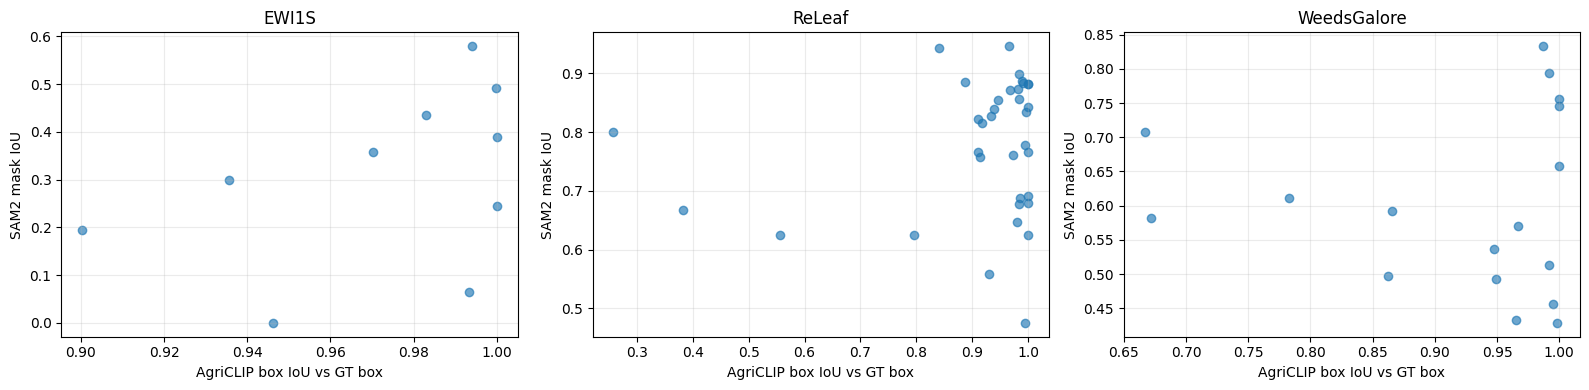

In [36]:
auto_df = per_image_df[per_image_df.prompt=="agriclip_auto"].copy()
localization_summary = auto_df.groupby("dataset").agg(
    n=("iou","count"),
    mean_auto_box_iou=("prompt_box_iou_vs_gt","mean"),
    median_auto_box_iou=("prompt_box_iou_vs_gt","median"),
    mean_auto_prompt_area=("prompt_area_fraction","mean"),
    median_auto_prompt_area=("prompt_area_fraction","median"),
    fraction_auto_box_ge_95pct=("prompt_area_fraction",lambda x: float((x>=0.95).mean())),
    mean_segmentation_iou=("iou","mean"),
).round(4)
display(localization_summary)
localization_summary.to_csv(OUTPUT_ROOT/"point7_localization_prompt_size_summary.csv")

fig, axes = plt.subplots(1,3,figsize=(16,4))
for ax, ds in zip(axes, sorted(auto_df.dataset.unique())):
    d=auto_df[auto_df.dataset==ds]
    ax.scatter(d.prompt_box_iou_vs_gt,d.iou,alpha=0.65)
    ax.set_title(ds)
    ax.set_xlabel("AgriCLIP box IoU vs GT box")
    ax.set_ylabel("SAM2 mask IoU")
    ax.grid(True,alpha=0.25)
plt.tight_layout()
plt.savefig(OUTPUT_ROOT/"point7_box_iou_vs_mask_iou.png",dpi=180,bbox_inches="tight")
plt.show()

## 10. Box perturbation sensitivity

In [37]:
if not perturb_df.empty:
    perturb_summary = perturb_df.groupby(["dataset","perturbation"]).agg(
        n=("iou","count"),
        mean_iou=("iou","mean"),
        std_iou=("iou","std"),
        mean_dice=("dice","mean"),
        mean_prompt_area=("prompt_area_fraction","mean"),
        mean_box_iou_vs_gt=("prompt_box_iou_vs_gt","mean"),
    ).reset_index().round(4)
    display(perturb_summary)
    perturb_summary.to_csv(OUTPUT_ROOT/"point7_perturbation_summary.csv",index=False)

    baseline_auto = auto_df[["dataset","image_id","iou"]].rename(columns={"iou":"auto_baseline_iou"})
    perturb_paired = perturb_df.merge(baseline_auto,on=["dataset","image_id"],how="left")
    perturb_paired["iou_change_vs_auto"] = perturb_paired["iou"]-perturb_paired["auto_baseline_iou"]
    perturb_paired["iou_drop_pp_vs_auto"] = 100*(perturb_paired["auto_baseline_iou"]-perturb_paired["iou"])
    sensitivity_summary = perturb_paired.groupby(["dataset","perturbation"]).agg(
        mean_iou_change=("iou_change_vs_auto","mean"),
        mean_iou_drop_pp=("iou_drop_pp_vs_auto","mean"),
        median_iou_drop_pp=("iou_drop_pp_vs_auto","median"),
        fraction_worse=("iou_drop_pp_vs_auto",lambda x:float((x>0).mean())),
    ).reset_index().round(4)
    display(sensitivity_summary)
    sensitivity_summary.to_csv(OUTPUT_ROOT/"point7_perturbation_sensitivity_summary.csv",index=False)

,dataset,perturbation,n,mean_iou,std_iou,mean_dice,mean_prompt_area,mean_box_iou_vs_gt
0,EWI1S,contract,10,0.3182,0.1370,0.4657,0.8101,0.8342
1,EWI1S,expand,10,0.3059,0.1837,0.4391,1.0000,0.9722
2,EWI1S,shift_down,10,0.3415,0.1532,0.4890,0.9500,0.9342
3,EWI1S,shift_left,10,0.3321,0.1579,0.4774,0.9500,0.9339
4,EWI1S,shift_right,10,0.3321,0.1561,0.4778,0.9500,0.9474
5,EWI1S,shift_up,10,0.3093,0.1834,0.4429,0.9500,0.9318
6,ReLeaf,contract,35,0.7816,0.1092,0.8731,0.8096,0.7953
7,ReLeaf,expand,35,0.7781,0.1150,0.8704,1.0000,0.9113
8,ReLeaf,shift_down,35,0.7776,0.1153,0.8701,0.9498,0.8805
9,ReLeaf,shift_left,35,0.7804,0.1141,0.8719,0.9501,0.8839


,dataset,perturbation,mean_iou_change,mean_iou_drop_pp,median_iou_drop_pp,fraction_worse
0,EWI1S,contract,0.0123,-1.2294,-0.0851,0.5000
1,EWI1S,expand,0.0000,0.0000,0.0000,0.0000
2,EWI1S,shift_down,0.0356,-3.5572,-0.0958,0.4000
3,EWI1S,shift_left,0.0262,-2.6226,0.1679,0.7000
4,EWI1S,shift_right,0.0262,-2.6189,-0.1106,0.4000
5,EWI1S,shift_up,0.0034,-0.3431,0.0889,0.6000
6,ReLeaf,contract,0.0035,-0.3512,0.1284,0.5429
7,ReLeaf,expand,0.0000,0.0000,0.0000,0.0000
8,ReLeaf,shift_down,-0.0005,0.0463,0.0693,0.7143
9,ReLeaf,shift_left,0.0023,-0.2271,-0.0395,0.3429


## 11. Empty-mask test cases (reported separately)

In [38]:
if not empty_df.empty:
    empty_summary = empty_df.groupby("dataset").agg(
        empty_images=("image_id","count"),
        full_image_mean_iou=("full_image_iou","mean"),
        auto_mean_iou=("auto_iou","mean"),
        full_image_mean_precision=("full_image_precision","mean"),
        auto_mean_precision=("auto_precision","mean"),
        full_image_mean_recall=("full_image_recall","mean"),
        auto_mean_recall=("auto_recall","mean"),
    ).round(4)
    display(empty_summary)
    empty_summary.to_csv(OUTPUT_ROOT/"point7_empty_mask_summary.csv")
else:
    print("No empty GT masks were encountered in the test partitions.")

No empty GT masks were encountered in the test partitions.


## 12. Qualitative examples: image, GT, prompts and SAM2 predictions


 ReLeaf


You are using a model of type sam2_video to instantiate a model of type sam2. This is not supported for all configurations of models and can yield errors.


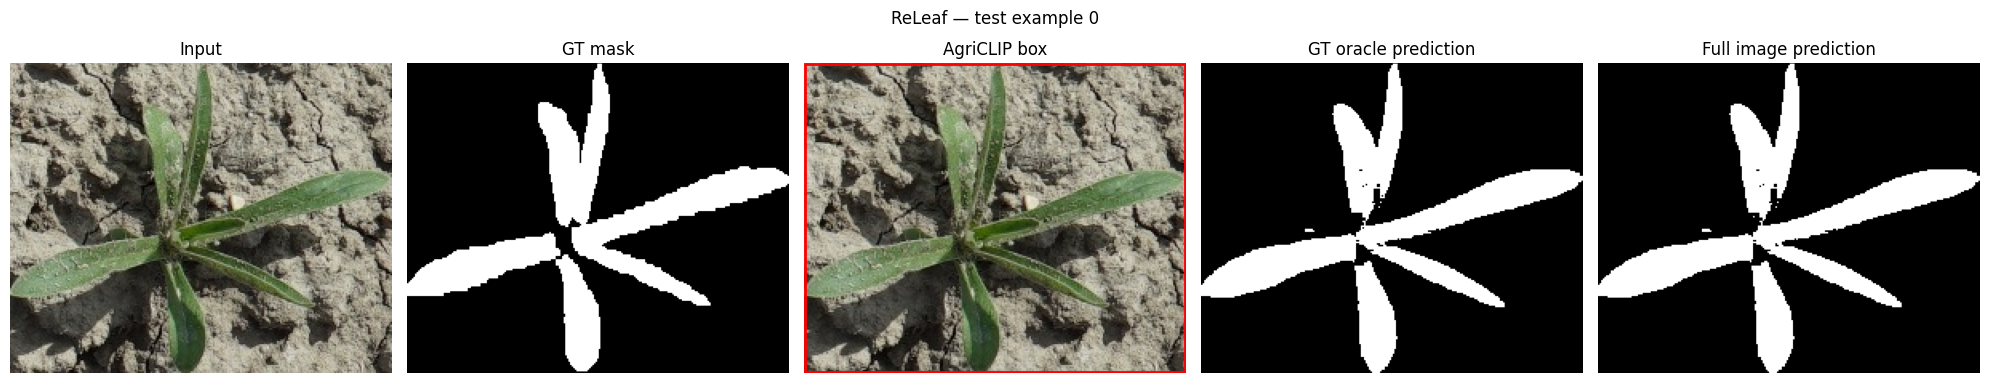

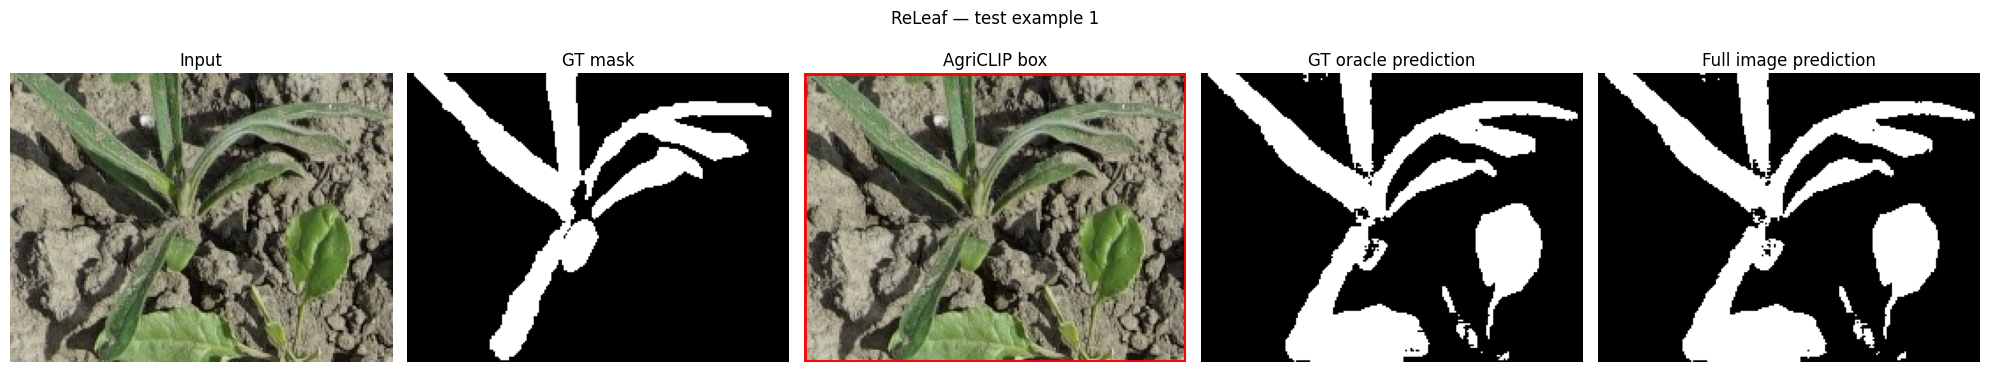


 WeedsGalore


You are using a model of type sam2_video to instantiate a model of type sam2. This is not supported for all configurations of models and can yield errors.


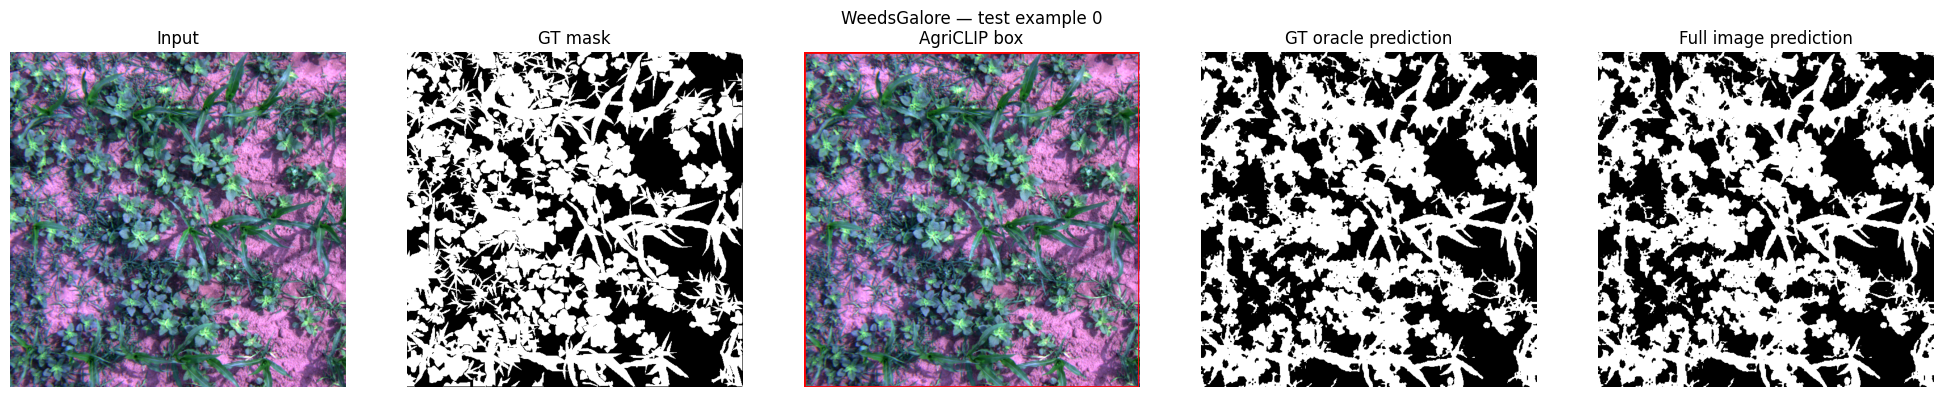

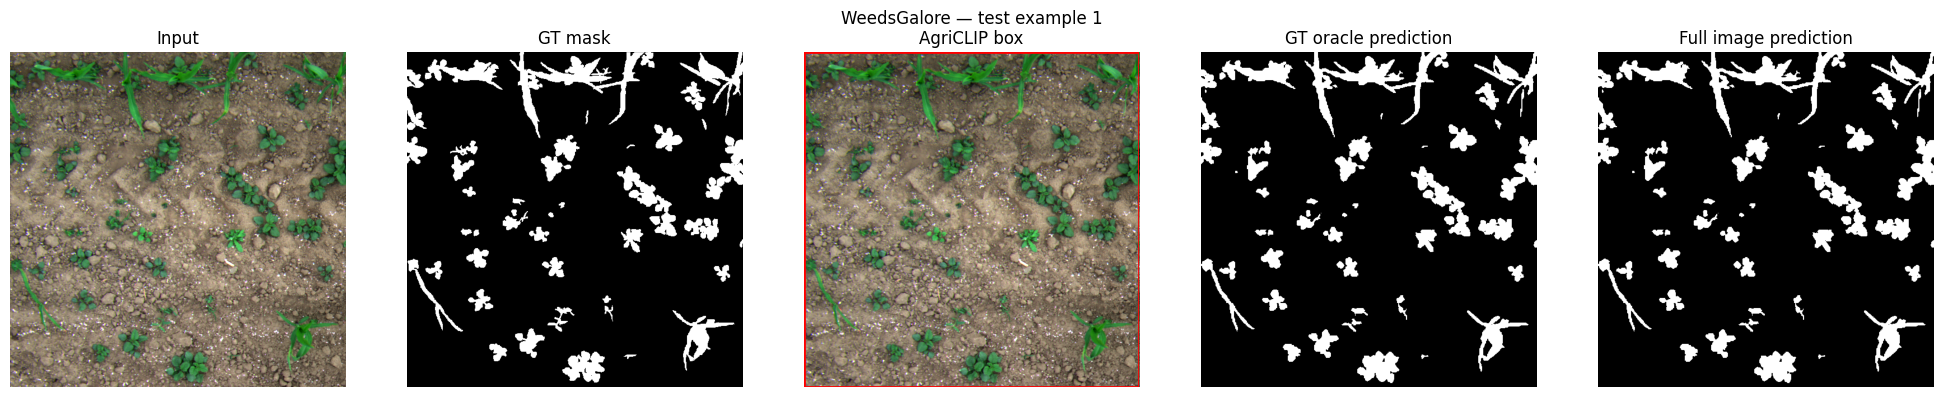


 EWI1S


You are using a model of type sam2_video to instantiate a model of type sam2. This is not supported for all configurations of models and can yield errors.


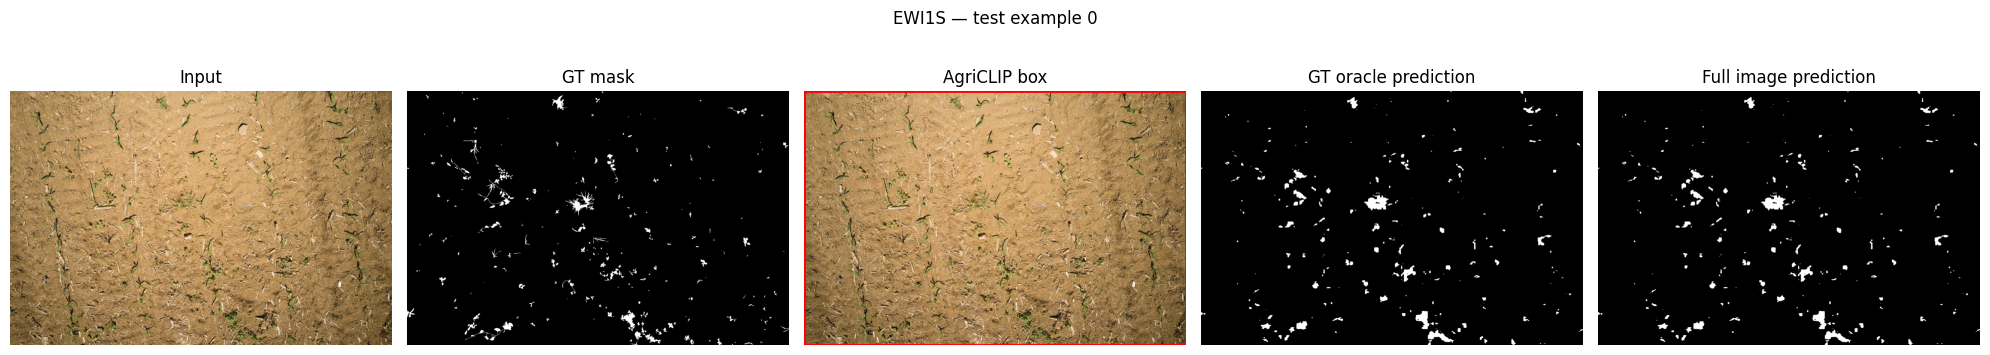

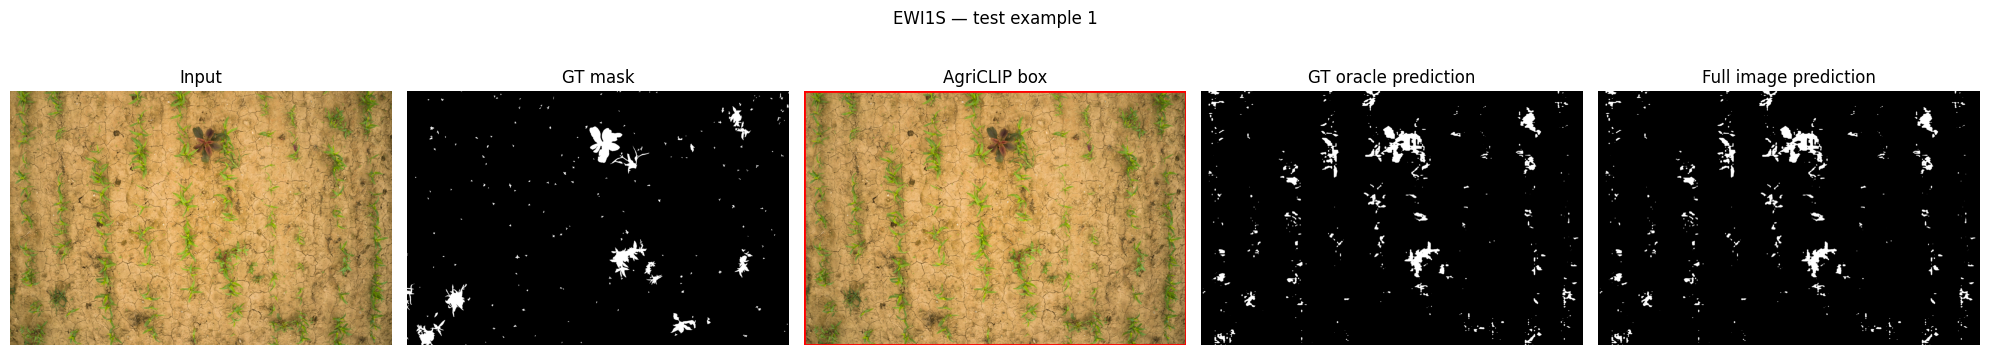

In [39]:
@torch.no_grad()
def visualize_point7_examples(dataset_name, n_examples=3):
    records = TEST_DATASETS[dataset_name]
    model = create_fresh_sam2()
    load_decoder_checkpoint(model, POINT7_CHECKPOINTS[dataset_name])
    shown=0
    for idx, record in enumerate(records):
        if shown>=n_examples: break
        image, gt = load_point7_sample(record,dataset_name)
        if gt.sum()==0: continue
        h,w=gt.shape
        gt_box=mask_to_box(gt)
        auto_box=clip_box_xyxy(generate_agriclip_box(image,top_k=TOP_K,margin=BOX_MARGIN)[0],w,h)
        full_box=full_image_box(w,h)
        preds={}
        for label,box in [("GT oracle",gt_box),("Full image",full_box),("AgriCLIP",auto_box)]:
            pred,_,_=sam2_predict_single_mask(model,image,box,MASK_THRESHOLD)
            preds[label]=pred
        fig,axs=plt.subplots(1,5,figsize=(20,4))
        axs[0].imshow(image); axs[0].set_title("Input")
        axs[1].imshow(gt,cmap="gray"); axs[1].set_title("GT mask")
        axs[2].imshow(image); axs[2].add_patch(plt.Rectangle((auto_box[0],auto_box[1]),auto_box[2]-auto_box[0],auto_box[3]-auto_box[1],fill=False,edgecolor="red",linewidth=2)); axs[2].set_title("AgriCLIP box")
        for ax,(label,pred) in zip(axs[3:],list(preds.items())[:2]):
            ax.imshow(pred,cmap="gray"); ax.set_title(label+" prediction")
        for ax in axs: ax.axis("off")
        plt.suptitle(f"{dataset_name} — test example {idx}")
        plt.tight_layout()
        plt.show()
        shown+=1
    del model
    if torch.cuda.is_available(): torch.cuda.empty_cache()

for ds in TEST_DATASETS:
    print("\n",ds)
    visualize_point7_examples(ds,n_examples=2)

## 13. Final protocol checks and export manifest

In [40]:
# Confirm that the target datasets have independent summaries and that no VegAnn headroom
# number has been hard-coded or reused.
print("DATASETS ANALYSED:", sorted(per_image_df.dataset.unique().tolist()))
print("PROMPT TYPES:", sorted(per_image_df.prompt.unique().tolist()))
print("PER-IMAGE NONEMPTY RECORDS:",len(per_image_df))
print("EMPTY-MASK RECORDS:",len(empty_df))
print("PERTURBATION RECORDS:",len(perturb_df))
print("\nFiles written to:",OUTPUT_ROOT.resolve())
for p in sorted(OUTPUT_ROOT.glob("point7_*")):
    print(f"{p.name:55s} {p.stat().st_size/1024:.1f} KB")

print("\nInterpretation reminder:")
print("- Oracle headroom is computed independently for each target dataset from paired test images.")
print("- GT boxes are privileged diagnostics, not deployable prompts.")
print("- Poor auto-box IoU with strong GT-box mask IoU suggests localization is a major failure source.")
print("- Poor GT-box mask IoU indicates limitations downstream of localization as well.")
print("- High GT component counts / low largest-component fractions describe fragmented vegetation structure.")
print("- Perturbation drops quantify sensitivity to imperfect prompt placement and extent.")

DATASETS ANALYSED: ['EWI1S', 'ReLeaf', 'WeedsGalore']
PROMPT TYPES: ['agriclip_auto', 'full_image', 'gt_oracle']
PER-IMAGE NONEMPTY RECORDS: 186
EMPTY-MASK RECORDS: 0
PERTURBATION RECORDS: 372

Files written to: /home/zahranadeem/thesis/point7_target_failure_diagnostics
point7_box_iou_vs_mask_iou.png                          100.9 KB
point7_box_perturbation_results.csv                     145.2 KB
point7_component_stratification.csv                     0.3 KB
point7_coverage_stratification.csv                      0.5 KB
point7_empty_mask_results.csv                           0.0 KB
point7_gt_structure_per_image.csv                       9.5 KB
point7_localization_prompt_size_summary.csv             0.3 KB
point7_oracle_headroom_summary.csv                      0.3 KB
point7_paired_per_image_deltas.csv                      10.1 KB
point7_per_image_results.csv                            68.5 KB
point7_perturbation_sensitivity_summary.csv             0.9 KB
point7_perturbation_summary.cs

## 14. Native-versus-oracle multimask candidate analysis (required extension)

This section repeats the **true three-candidate SAM2 analysis** on ReLeaf, WeedsGalore and EWI1S. For each image and each available prompt type (GT-derived box, full-image box, AgriCLIP automatic box), SAM2 returns all candidate masks with its predicted-IoU scores. The **native** choice is the candidate with the highest SAM2 score; the **oracle** choice is the candidate with the highest IoU against that image's ground-truth mask.

The oracle uses ground truth only for retrospective analysis and is not an inference-time method. The target-domain headroom is recomputed independently for each dataset and prompt type. The previously reported **+1.296 percentage-point VegAnn result remains VegAnn-specific** and is not copied or assumed here. Empty-GT images are reported separately: a GT-derived box is undefined for them, so candidate analysis for those images is performed only with full-image and automatic boxes.

This is an additional SAM2 pass over the test sets and can be computationally expensive. Results are checkpointed to CSV after every image so the run can be recovered if interrupted. Set `MAX_IMAGES_PER_DATASET` above to a small integer for a smoke test; leave it as `None` for complete test partitions.

In [41]:
# ============================================================
# ALL-CANDIDATE SAM2 INFERENCE
# ============================================================

@torch.no_grad()
def sam2_predict_all_candidates(model, image, box, threshold=MASK_THRESHOLD):
    """Return all SAM2 multimask candidates and native confidence scores."""
    box = np.asarray(box, dtype=np.float32).reshape(-1)
    if box.shape != (4,):
        raise ValueError(f"Expected [x1,y1,x2,y2], got shape {box.shape}")

    inputs = sam2_processor(
        images=image,
        input_boxes=[[box.tolist()]],
        return_tensors="pt"
    )
    inputs = {
        key: value.to(DEVICE) if torch.is_tensor(value) else value
        for key, value in inputs.items()
    }
    outputs = model(**inputs, multimask_output=True)

    candidate_scores = outputs.iou_scores[0, 0].detach().float().cpu().numpy()
    height = int(inputs["original_sizes"][0, 0].item())
    width = int(inputs["original_sizes"][0, 1].item())
    candidate_logits = outputs.pred_masks[0, 0]

    predictions = []
    probabilities = []
    for candidate_idx in range(candidate_logits.shape[0]):
        probability = torch.sigmoid(candidate_logits[candidate_idx])
        probability = F.interpolate(
            probability[None, None], size=(height, width),
            mode="bilinear", align_corners=False
        )[0, 0]
        probabilities.append(probability.detach().cpu().numpy())
        predictions.append((probability >= threshold).cpu().numpy().astype(np.uint8))

    if len(predictions) != len(candidate_scores):
        raise RuntimeError(
            f"Candidate count mismatch: {len(predictions)} masks vs "
            f"{len(candidate_scores)} scores"
        )
    return predictions, candidate_scores


def candidate_iou(prediction, target):
    """Image-level IoU, defining empty/empty as 1.0 for explicit empty cases."""
    prediction = np.asarray(prediction).astype(bool)
    target = np.asarray(target).astype(bool)
    intersection = np.logical_and(prediction, target).sum()
    union = np.logical_or(prediction, target).sum()
    if union == 0:
        return 1.0
    return float(intersection / union)

print("All-candidate SAM2 function ready.")

All-candidate SAM2 function ready.


In [42]:
# ============================================================
# RUN TARGET-DATASET NATIVE VS ORACLE CANDIDATE ANALYSIS
# ============================================================

CANDIDATE_DETAIL_PATH = OUTPUT_ROOT / "point7_multimask_candidate_details.csv"
CANDIDATE_SELECTION_PATH = OUTPUT_ROOT / "point7_multimask_native_vs_oracle_per_image.csv"

# Resume-safe: existing rows are retained when a run is restarted.
if CANDIDATE_DETAIL_PATH.exists():
    candidate_detail_rows = pd.read_csv(CANDIDATE_DETAIL_PATH).to_dict("records")
else:
    candidate_detail_rows = []
if CANDIDATE_SELECTION_PATH.exists():
    candidate_selection_rows = pd.read_csv(CANDIDATE_SELECTION_PATH).to_dict("records")
else:
    candidate_selection_rows = []

completed_candidate_keys = {
    (str(r["dataset"]), str(r["image_id"]), str(r["prompt"]))
    for r in candidate_selection_rows
}

@torch.no_grad()
def run_target_candidate_analysis(dataset_name, records):
    checkpoint_path = POINT7_CHECKPOINTS[dataset_name]
    if not Path(checkpoint_path).exists():
        raise FileNotFoundError(f"Missing {dataset_name} checkpoint: {checkpoint_path}")

    model = create_fresh_sam2()
    checkpoint_obj = load_decoder_checkpoint(model, checkpoint_path)
    print(f"\n{dataset_name}: multimask candidate analysis using {checkpoint_path}")
    print("Checkpoint metadata keys:", list(checkpoint_obj.keys())[:12] if isinstance(checkpoint_obj, dict) else type(checkpoint_obj))

    run_records = list(records)
    if MAX_IMAGES_PER_DATASET is not None:
        run_records = run_records[:MAX_IMAGES_PER_DATASET]

    for image_idx, record in enumerate(tqdm(run_records, desc=f"{dataset_name} candidates")):
        sample_id = str(record.get("image_path", record.get("id", image_idx)))
        image, gt = load_point7_sample(record, dataset_name)
        height, width = gt.shape
        gt_is_empty = bool(gt.sum() == 0)

        # All three prompt conditions use the SAME loaded target-specific checkpoint.
        prompt_boxes = {
            "full_image": full_image_box(width, height),
            "agriclip_auto": clip_box_xyxy(
                generate_agriclip_box(image, top_k=TOP_K, margin=BOX_MARGIN)[0],
                width, height
            ),
        }
        if not gt_is_empty:
            prompt_boxes["gt_oracle"] = mask_to_box(gt)

        for prompt_name, prompt_box in prompt_boxes.items():
            key = (dataset_name, sample_id, prompt_name)
            if key in completed_candidate_keys:
                continue

            predictions, sam2_scores = sam2_predict_all_candidates(
                model, image, prompt_box, threshold=MASK_THRESHOLD
            )
            candidate_ious = [candidate_iou(pred, gt) for pred in predictions]
            native_idx = int(np.argmax(sam2_scores))
            oracle_idx = int(np.argmax(candidate_ious))
            native_iou = float(candidate_ious[native_idx])
            oracle_iou = float(candidate_ious[oracle_idx])

            for candidate_idx, (pred, sam2_score, true_iou) in enumerate(
                zip(predictions, sam2_scores, candidate_ious)
            ):
                candidate_detail_rows.append({
                    "dataset": dataset_name,
                    "image_id": sample_id,
                    "prompt": prompt_name,
                    "candidate_index": int(candidate_idx),
                    "sam2_predicted_iou_score": float(sam2_score),
                    "ground_truth_iou": float(true_iou),
                    "is_native_selected": bool(candidate_idx == native_idx),
                    "is_oracle_selected": bool(candidate_idx == oracle_idx),
                    "predicted_vegetation_coverage": float(np.asarray(pred).sum() / (height * width)),
                    "gt_is_empty": gt_is_empty,
                })

            candidate_selection_rows.append({
                "dataset": dataset_name,
                "image_id": sample_id,
                "prompt": prompt_name,
                "num_candidates": len(predictions),
                "native_candidate_index": native_idx,
                "oracle_candidate_index": oracle_idx,
                "native_iou": native_iou,
                "oracle_iou": oracle_iou,
                "oracle_headroom_pp": 100.0 * (oracle_iou - native_iou),
                "native_selected_oracle_best": bool(native_idx == oracle_idx),
                "native_sam2_score": float(sam2_scores[native_idx]),
                "oracle_candidate_sam2_score": float(sam2_scores[oracle_idx]),
                "gt_is_empty": gt_is_empty,
                "prompt_area_fraction": box_area_fraction(prompt_box, width, height),
            })
            completed_candidate_keys.add(key)

            # Save after each prompt, not only at the end of a dataset.
            pd.DataFrame(candidate_detail_rows).to_csv(CANDIDATE_DETAIL_PATH, index=False)
            pd.DataFrame(candidate_selection_rows).to_csv(CANDIDATE_SELECTION_PATH, index=False)

    del model
    if torch.cuda.is_available():
        torch.cuda.empty_cache()

for candidate_dataset_name, candidate_records in TEST_DATASETS.items():
    run_target_candidate_analysis(candidate_dataset_name, candidate_records)

candidate_detail_df = pd.DataFrame(candidate_detail_rows)
candidate_selection_df = pd.DataFrame(candidate_selection_rows)
print("\nCandidate detail rows:", len(candidate_detail_df))
print("Per-image prompt comparisons:", len(candidate_selection_df))
print("Saved:", CANDIDATE_DETAIL_PATH)
print("Saved:", CANDIDATE_SELECTION_PATH)

You are using a model of type sam2_video to instantiate a model of type sam2. This is not supported for all configurations of models and can yield errors.



ReLeaf: multimask candidate analysis using /home/zahranadeem/thesis/sam2_domain_finetuning/VegAnn_to_ReLeaf/best_mask_decoder.pt
Checkpoint metadata keys: ['experiment_name', 'epoch', 'model_name', 'starting_checkpoint', 'train_samples', 'val_samples', 'learning_rate', 'box_jitter_fraction', 'mask_decoder_state_dict', 'optimizer_state_dict', 'best_mean_iou', 'history']


ReLeaf candidates:   0%|          | 0/35 [00:00<?, ?it/s]

You are using a model of type sam2_video to instantiate a model of type sam2. This is not supported for all configurations of models and can yield errors.



WeedsGalore: multimask candidate analysis using /home/zahranadeem/thesis/sam2_domain_finetuning/VegAnn_to_WeedsGalore/best_mask_decoder.pt
Checkpoint metadata keys: ['experiment_name', 'epoch', 'model_name', 'starting_checkpoint', 'train_samples', 'val_samples', 'learning_rate', 'box_jitter_fraction', 'mask_decoder_state_dict', 'optimizer_state_dict', 'best_mean_iou', 'history']


WeedsGalore candidates:   0%|          | 0/17 [00:00<?, ?it/s]

You are using a model of type sam2_video to instantiate a model of type sam2. This is not supported for all configurations of models and can yield errors.



EWI1S: multimask candidate analysis using /home/zahranadeem/thesis/sam2_domain_finetuning/VegAnn_to_EWI1S/best_mask_decoder.pt
Checkpoint metadata keys: ['experiment_name', 'epoch', 'model_name', 'starting_checkpoint', 'train_samples', 'val_samples', 'learning_rate', 'box_jitter_fraction', 'mask_decoder_state_dict', 'optimizer_state_dict', 'best_mean_iou', 'history']


EWI1S candidates:   0%|          | 0/10 [00:00<?, ?it/s]


Candidate detail rows: 558
Per-image prompt comparisons: 186
Saved: /home/zahranadeem/thesis/point7_target_failure_diagnostics/point7_multimask_candidate_details.csv
Saved: /home/zahranadeem/thesis/point7_target_failure_diagnostics/point7_multimask_native_vs_oracle_per_image.csv


## 15. Candidate-selection results and target-specific oracle headroom

The following tables report native-versus-oracle performance separately for each target dataset and prompt. The main target-domain conclusion should be based on the `agriclip_auto` rows because those correspond to the deployable pipeline; GT-box and full-image results are diagnostic prompt conditions. The `gt_oracle` prompt is unavailable on empty-GT images by definition. Do not quote the VegAnn +1.296 pp result as a target-domain result.

In [43]:
# ============================================================
# SUMMARIZE NATIVE VS ORACLE CANDIDATE SELECTION
# ============================================================

if candidate_selection_df.empty:
    raise RuntimeError("No candidate-selection rows found. Run the candidate analysis cell first.")

candidate_nonempty_df = candidate_selection_df[~candidate_selection_df.gt_is_empty].copy()

candidate_summary_df = (
    candidate_nonempty_df
    .groupby(["dataset", "prompt"])
    .agg(
        n_images=("image_id", "nunique"),
        mean_native_iou=("native_iou", "mean"),
        mean_oracle_iou=("oracle_iou", "mean"),
        mean_oracle_headroom_pp=("oracle_headroom_pp", "mean"),
        median_oracle_headroom_pp=("oracle_headroom_pp", "median"),
        native_selected_oracle_best_rate=("native_selected_oracle_best", "mean"),
        mean_native_sam2_score=("native_sam2_score", "mean"),
        mean_prompt_area_fraction=("prompt_area_fraction", "mean"),
    )
    .reset_index()
)
candidate_summary_df["mean_native_iou_pct"] = 100 * candidate_summary_df["mean_native_iou"]
candidate_summary_df["mean_oracle_iou_pct"] = 100 * candidate_summary_df["mean_oracle_iou"]
candidate_summary_df["native_selected_oracle_best_pct"] = 100 * candidate_summary_df["native_selected_oracle_best_rate"]
candidate_summary_df["mean_prompt_area_pct"] = 100 * candidate_summary_df["mean_prompt_area_fraction"]
candidate_summary_df = candidate_summary_df.round(4)
display(candidate_summary_df)
candidate_summary_df.to_csv(OUTPUT_ROOT / "point7_multimask_native_vs_oracle_summary.csv", index=False)

# Primary deployment-pipeline result: automatic AgriCLIP prompt, independently per target domain.
auto_candidate_summary = candidate_summary_df[
    candidate_summary_df.prompt == "agriclip_auto"
][[
    "dataset", "n_images", "mean_native_iou_pct", "mean_oracle_iou_pct",
    "mean_oracle_headroom_pp", "median_oracle_headroom_pp",
    "native_selected_oracle_best_pct"
]].copy()
print("\nTARGET-DATASET ORACLE HEADROOM — AUTOMATIC AGRICLIP BOX")
display(auto_candidate_summary)
auto_candidate_summary.to_csv(
    OUTPUT_ROOT / "point7_target_dataset_automatic_box_oracle_headroom.csv",
    index=False
)

# Candidate-index diagnostics: how often SAM2's native confidence picks each candidate,
# and how often each candidate is actually best under GT IoU.
candidate_frequency_df = (
    candidate_detail_df[~candidate_detail_df.gt_is_empty]
    .groupby(["dataset", "prompt", "candidate_index"])
    .agg(
        candidate_rows=("ground_truth_iou", "count"),
        native_selection_count=("is_native_selected", "sum"),
        oracle_selection_count=("is_oracle_selected", "sum"),
        mean_true_iou=("ground_truth_iou", "mean"),
        mean_sam2_score=("sam2_predicted_iou_score", "mean"),
    )
    .reset_index()
)
candidate_frequency_df.to_csv(
    OUTPUT_ROOT / "point7_multimask_candidate_frequency.csv", index=False
)
display(candidate_frequency_df.round(4))

# Per-image headroom distribution, useful for diagnosing whether mean headroom hides variation.
headroom_distribution = candidate_nonempty_df.groupby(["dataset", "prompt"])["oracle_headroom_pp"].describe().round(4)
display(headroom_distribution)
headroom_distribution.to_csv(OUTPUT_ROOT / "point7_multimask_headroom_distribution.csv")

print("\nInterpretation guardrail:")
print("+1.296 pp is the previously established VegAnn result only.")
print("Use the independently computed ReLeaf, WeedsGalore and EWI1S values above for target-domain conclusions.")

,dataset,prompt,n_images,mean_native_iou,mean_oracle_iou,mean_oracle_headroom_pp,median_oracle_headroom_pp,native_selected_oracle_best_rate,mean_native_sam2_score,mean_prompt_area_fraction,mean_native_iou_pct,mean_oracle_iou_pct,native_selected_oracle_best_pct,mean_prompt_area_pct
0,EWI1S,agriclip_auto,10,0.1836,0.1969,1.3270,1.2872,0.2000,0.8180,1.0000,18.3586,19.6855,20.0000,100.0000
1,EWI1S,full_image,10,0.1836,0.1969,1.3270,1.2872,0.2000,0.8180,1.0000,18.3586,19.6855,20.0000,100.0000
2,EWI1S,gt_oracle,10,0.1830,0.1964,1.3360,1.1157,0.1000,0.8174,0.9722,18.3025,19.6384,10.0000,97.2243
3,ReLeaf,agriclip_auto,35,0.7791,0.7853,0.6212,0.2332,0.3429,0.9532,1.0000,77.9113,78.5325,34.2857,100.0000
4,ReLeaf,full_image,35,0.7791,0.7853,0.6212,0.2332,0.3429,0.9532,1.0000,77.9113,78.5325,34.2857,100.0000
5,ReLeaf,gt_oracle,35,0.7946,0.8014,0.6758,0.2098,0.3143,0.9531,0.9113,79.4649,80.1407,31.4286,91.1313
6,WeedsGalore,agriclip_auto,17,0.5711,0.5746,0.3568,0.2134,0.3529,0.8956,1.0000,57.1055,57.4622,35.2941,100.0000
7,WeedsGalore,full_image,17,0.5711,0.5746,0.3568,0.2134,0.3529,0.8956,1.0000,57.1055,57.4622,35.2941,100.0000
8,WeedsGalore,gt_oracle,17,0.5750,0.5796,0.4578,0.2518,0.3529,0.8934,0.9200,57.5028,57.9606,35.2941,91.9979



TARGET-DATASET ORACLE HEADROOM — AUTOMATIC AGRICLIP BOX


,dataset,n_images,mean_native_iou_pct,mean_oracle_iou_pct,mean_oracle_headroom_pp,median_oracle_headroom_pp,native_selected_oracle_best_pct
0,EWI1S,10,18.3586,19.6855,1.3270,1.2872,20.0000
3,ReLeaf,35,77.9113,78.5325,0.6212,0.2332,34.2857
6,WeedsGalore,17,57.1055,57.4622,0.3568,0.2134,35.2941


,dataset,prompt,candidate_index,candidate_rows,native_selection_count,oracle_selection_count,mean_true_iou,mean_sam2_score
0,EWI1S,agriclip_auto,0,10,0,3,0.1699,0.4682
1,EWI1S,agriclip_auto,1,10,3,3,0.1816,0.7858
2,EWI1S,agriclip_auto,2,10,7,4,0.1880,0.8075
3,EWI1S,full_image,0,10,0,3,0.1699,0.4682
4,EWI1S,full_image,1,10,3,3,0.1816,0.7858
5,EWI1S,full_image,2,10,7,4,0.1880,0.8075
6,EWI1S,gt_oracle,0,10,0,4,0.1707,0.4747
7,EWI1S,gt_oracle,1,10,2,3,0.1800,0.7844
8,EWI1S,gt_oracle,2,10,8,3,0.1871,0.8068
9,ReLeaf,agriclip_auto,0,35,5,10,0.7670,0.9202


count    mean     std  min     25%     50%     75%  \
dataset     prompt                                                              
EWI1S       agriclip_auto   10.0  1.3270  1.2315  0.0  0.3496  1.2872  1.6312   
            full_image      10.0  1.3270  1.2315  0.0  0.3496  1.2872  1.6312   
            gt_oracle       10.0  1.3360  1.2448  0.0  0.3241  1.1157  1.6591   
ReLeaf      agriclip_auto   35.0  0.6212  0.8839  0.0  0.0000  0.2332  0.9328   
            full_image      35.0  0.6212  0.8839  0.0  0.0000  0.2332  0.9328   
            gt_oracle       35.0  0.6758  0.9696  0.0  0.0000  0.2098  0.8785   
WeedsGalore agriclip_auto   17.0  0.3568  0.4788  0.0  0.0000  0.2134  0.4007   
            full_image      17.0  0.3568  0.4788  0.0  0.0000  0.2134  0.4007   
            gt_oracle       17.0  0.4578  0.6310  0.0  0.0000  0.2518  0.5728   

                              max  
dataset     prompt                 
EWI1S       agriclip_auto  3.7121  
            full_image     3.7121  
            gt_oracle      3.7154  
ReLeaf      agriclip_auto  2.9027  
            full_image     2.9027  
            gt_oracle      3.3770  
WeedsGalore agriclip_auto  1.6448  
            full_image     1.6448  
            gt_oracle      2.3593


Interpretation guardrail:
+1.296 pp is the previously established VegAnn result only.
Use the independently computed ReLeaf, WeedsGalore and EWI1S values above for target-domain conclusions.
